# PPMI Modality Analysis: Neuropsychological & Cognitive Function
**Notebook**: `eda_pca_cognitive.ipynb`  
**Modality Group**: `cognitive` (10 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Standardized psychometric batteries spanning MoCA, SDMT processing speed, Hopkins verbal learning, Benton JLO visuospatial, letter-number sequencing, semantic and lexical fluency, clock drawing, and trail making.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'cognitive', Dynamic repository root: ppmi")

Environment initialized. Modality: 'cognitive', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Neuropsychological & Cognitive Function
The authoritative catalog assigns exactly **10 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'cognitive']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,neuropsychological_Montreal_Cognitive_Assessme...,Montreal_Cognitive_Assessment__MoCA__09Nov2026...,Yes,COMPLETED,COMPLETED,COMPLETED (23 feats)
1,neuropsychological_Symbol_Digit_Modalities_Tes...,Symbol_Digit_Modalities_Test_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
2,neuropsychological_Hopkins_Verbal_Learning_Tes...,Hopkins_Verbal_Learning_Test_-_Revised_09Nov20...,Yes,COMPLETED,COMPLETED,COMPLETED (7 feats)
3,neuropsychological_Benton_Judgement_of_Line_Or...,Benton_Judgement_of_Line_Orientation_09Nov2026...,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
4,neuropsychological_Letter_-_Number_Sequencing_...,Letter_-_Number_Sequencing_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (15 feats)
5,other_cognitive_Cognitive_Categorization_09Nov...,Cognitive_Categorization_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
6,neuropsychological_Modified_Semantic_Fluency_0...,Modified_Semantic_Fluency_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
7,neuropsychological_Lexical_Fluency_09Nov2026_csv,Lexical_Fluency_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (3 feats)
8,neuropsychological_Clock_Drawing_09Nov2026_csv,Clock_Drawing_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (7 feats)
9,neuropsychological_Trail_Making_A_and_B_09Nov2...,Trail_Making_A_and_B_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (4 feats)


Total units cataloged: 10 | EDA Completed: 10 | PCA Completed: 6


---
## 2.1. Unit: `Montreal_Cognitive_Assessment__MoCA__09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv`
- **Source Path**: `neuropsychological/Montreal_Cognitive_Assessment__MoCA__09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Primary EDA` | **Role**: `Primary global cognitive screening tool (score 0–30) assessing short-term memory, visuospatial abilities, executive function, phonemic fluency, attention, and orientation. Crucial for identifying Mild Cognitive Impairment (MCI) and dementia onset.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Montreal_Cognitive_Assessment__MoCA__09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 10,698 analyzed rows x 36 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 21,426 (5,815 participants)
  - PD Retained:  8,479 rows (1,684 participants)
  - HC Retained:  2,219 rows (336 participants)
  - Non-Target Excluded: 9,913 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  815 rows

Exact Variable Schema & Storage Types (36 columns):
Showing first 20 of 36 columns (complete schema committed to neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,698",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,24,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,195,Date / Timestamp / Visit
5,MCAALTTM,float64,6,0.1%,2,Analytical Numeric Measurement
6,MCACUBE,float64,4,0.0%,2,Analytical Numeric Measurement
7,MCACLCKC,float64,6,0.1%,2,Analytical Numeric Measurement
8,MCACLCKN,float64,6,0.1%,2,Analytical Numeric Measurement
9,MCACLCKH,float64,6,0.1%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,27
Identifier,3
Date / Timestamp / Visit,3
Administrative Metadata,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 181 / 385,128 (0.05%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (28 total, top 8):


,name,missing_count,missing_percent,variable_role
32,MCATOT,33,0.3%,Analytical Numeric Measurement
24,MCAREC4,10,0.1%,Analytical Numeric Measurement
23,MCAREC3,9,0.1%,Analytical Numeric Measurement
21,MCAREC1,9,0.1%,Analytical Numeric Measurement
22,MCAREC2,9,0.1%,Analytical Numeric Measurement
30,MCAPLACE,7,0.1%,Analytical Numeric Measurement
26,MCADATE,7,0.1%,Date / Timestamp / Visit
25,MCAREC5,8,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,479"
1,HC,"2,219"



Numeric Summaries & Outlier Diagnostics (27 continuous/discrete features):
Showing top 10 of 27 features (full distribution profiles in neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,MCAALTTM,0.875,0.331,0.0,1.0,1.0,-2.265,Strongly skewed (negative),"1,339",0
1,MCACUBE,0.723,0.448,0.0,1.0,1.0,-0.994,Moderately skewed (negative),0,0
2,MCACLCKC,0.966,0.181,0.0,1.0,1.0,-5.140,Strongly skewed (negative),364,364
3,MCACLCKN,0.893,0.309,0.0,1.0,1.0,-2.548,Strongly skewed (negative),"1,141",0
4,MCACLCKH,0.796,0.403,0.0,1.0,1.0,-1.467,Strongly skewed (negative),"2,184",0
5,MCALION,0.995,0.068,0.0,1.0,1.0,-14.525,Strongly skewed (negative),50,50
6,MCARHINO,0.949,0.220,0.0,1.0,1.0,-4.071,Strongly skewed (negative),548,548
7,MCACAMEL,0.991,0.092,0.0,1.0,1.0,-10.644,Strongly skewed (negative),92,92
8,MCAFDS,0.949,0.221,0.0,1.0,1.0,-4.067,Strongly skewed (negative),549,549
9,MCABDS,0.910,0.286,0.0,1.0,1.0,-2.875,Strongly skewed (negative),958,958


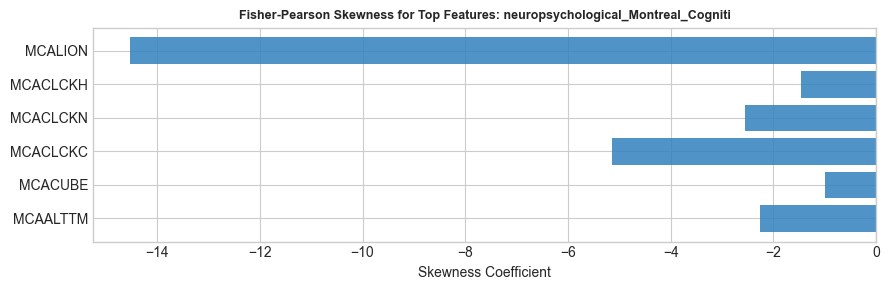

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Montreal_Cognitive_Assessment__MoCA__09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Montreal_Cogniti", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `23` continuous analytical measurements
- **Excluded Features**: `13` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `9.8%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,9.82%,9.82%
1,PC2,7.14%,16.97%
2,PC3,6.36%,23.33%
3,PC4,5.31%,28.64%
4,PC5,5.17%,33.81%



Top PC1 Feature Loadings:


,feature_name,loading
0,MCAVFNUM,0.3693
1,MCAVF,0.3625
2,MCAREC3,0.3368
3,MCAREC2,0.3003
4,MCAREC5,0.2844


Scree & Eigenvector Loadings Plot:


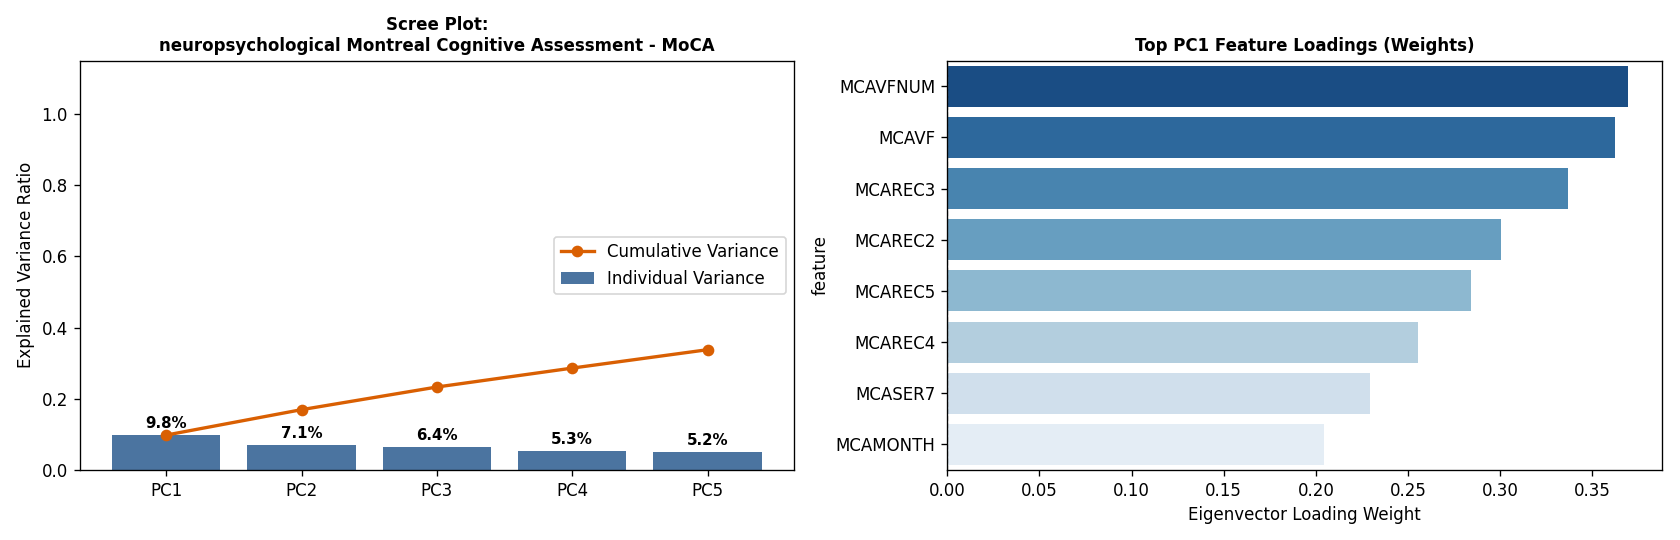

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


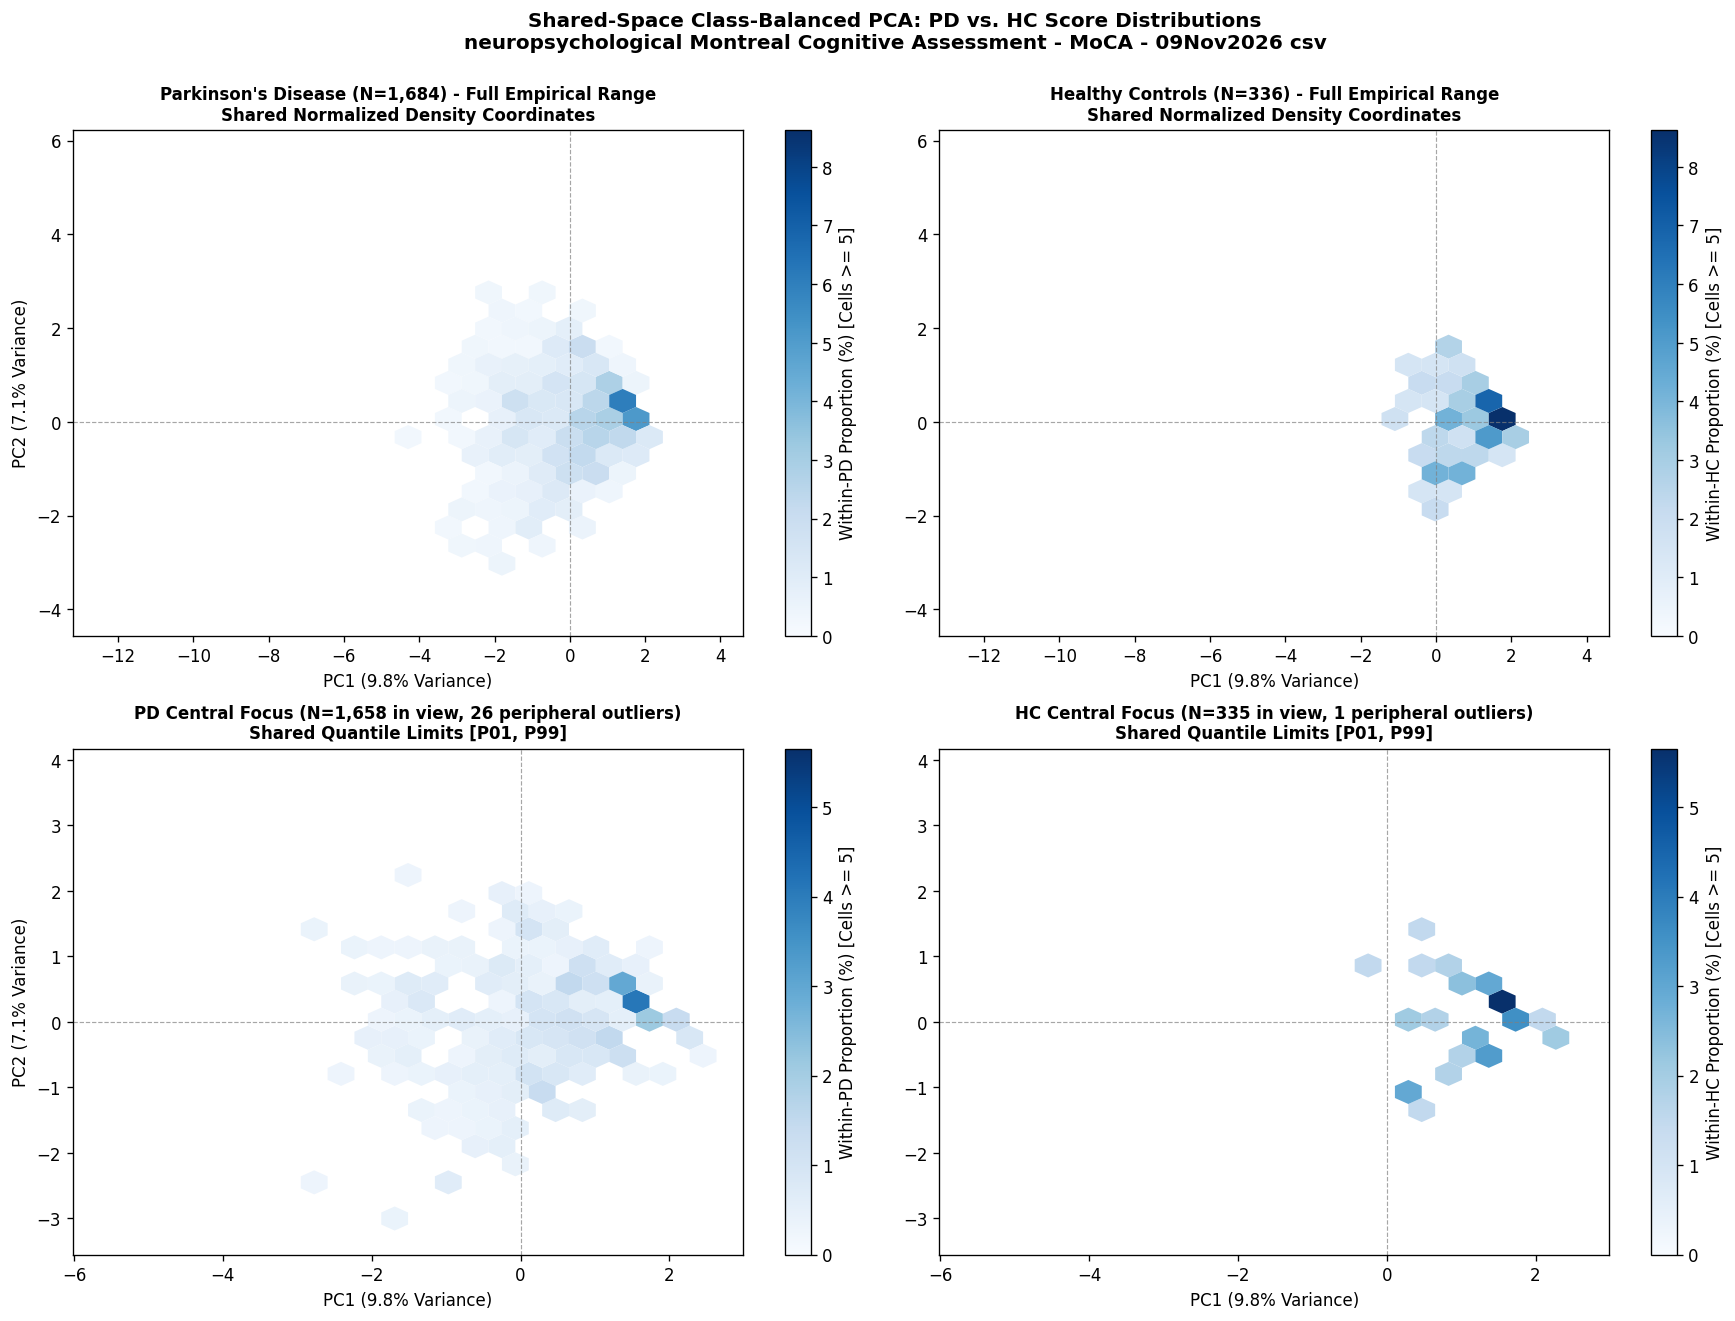

In [4]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Montreal_Cognitive_Assessment__MoCA__09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.2. Unit: `Symbol_Digit_Modalities_Test_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv`
- **Source Path**: `neuropsychological/Symbol_Digit_Modalities_Test_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `SDMT assesses complex visual scanning, cognitive processing speed, and divided attention. One of the earliest and most sensitive cognitive markers of decline.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: neuropsychological/Symbol_Digit_Modalities_Test_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,350 analyzed rows x 13 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,494 (5,323 participants)
  - PD Retained:  8,144 rows (1,676 participants)
  - HC Retained:  2,206 rows (336 participants)
  - Non-Target Excluded: 9,811 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  333 rows

Exact Variable Schema & Storage Types (13 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,350",Identifier
1,PATNO,int64,0,0.0%,"2,012",Identifier
2,EVENT_ID,object,0,0.0%,23,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,SDMTOTAL,float64,8,0.1%,92,Analytical Numeric Measurement
6,SDMTVRSN,float64,5,0.1%,2,Instrument Version
7,AGE_ASSESS_SDM,float64,8,0.1%,70,Demographic / Covariate
8,DVSD_SDM,float64,24,0.2%,134,Analytical Numeric Measurement
9,DVT_SDM,float64,24,0.2%,134,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Identifier,3
Analytical Numeric Measurement,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Instrument Version,1
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 69 / 134,550 (0.05%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (5 total, top 8):


,name,missing_count,missing_percent,variable_role
9,DVT_SDM,24,0.2%,Analytical Numeric Measurement
8,DVSD_SDM,24,0.2%,Analytical Numeric Measurement
5,SDMTOTAL,8,0.1%,Analytical Numeric Measurement
7,AGE_ASSESS_SDM,8,0.1%,Demographic / Covariate
6,SDMTVRSN,5,0.1%,Instrument Version



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,144"
1,HC,"2,206"



Numeric Summaries & Outlier Diagnostics (5 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,SDMTOTAL,41.484,12.356,0.0,42.0,102.0,-0.153,Approximately symmetric,187,81
1,SDMTVRSN,1.457,0.498,1.0,1.0,2.0,0.172,Approximately symmetric,0,0
2,AGE_ASSESS_SDM,65.043,10.120,29.0,66.0,98.0,-0.510,Moderately skewed (negative),182,65
3,DVSD_SDM,-0.329,1.142,-3.0,-0.3,3.0,-0.003,Approximately symmetric,128,0
4,DVT_SDM,46.757,11.391,20.0,47.0,80.0,-0.007,Approximately symmetric,107,0


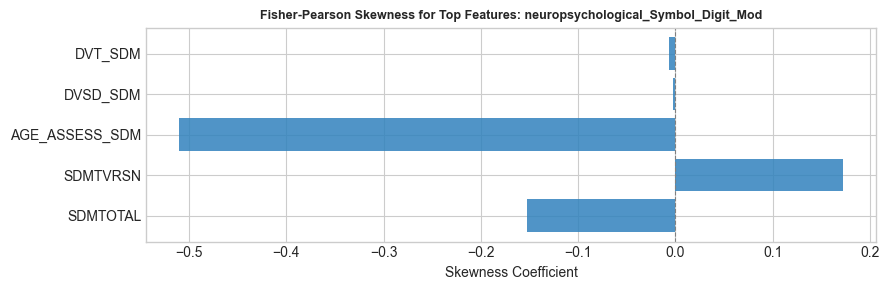

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Symbol_Digit_Modalities_Test_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Symbol_Digit_Modalities_Test_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Symbol_Digit_Mod", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (1 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [6]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (1 < 2)
Features Evaluated: 1 included, 12 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,SDMTVRSN,"Identifier, date, visit, demographic, instrume..."
6,AGE_ASSESS_SDM,"Identifier, date, visit, demographic, instrume..."
7,ORIG_ENTRY,"Identifier, date, visit, demographic, instrume..."
8,LAST_UPDATE,"Identifier, date, visit, demographic, instrume..."
9,TARGET_COHORT_STRATIFICATION,"Identifier, date, visit, demographic, instrume..."


---
## 2.3. Unit: `Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv`
- **Source Path**: `neuropsychological/Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `HVLT-R assesses verbal episodic learning and memory across 3 immediate recall trials, delayed recall, and recognition discrimination index.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 10,380 analyzed rows x 21 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,545 (5,328 participants)
  - PD Retained:  8,173 rows (1,679 participants)
  - HC Retained:  2,207 rows (336 participants)
  - Non-Target Excluded: 9,832 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  333 rows

Exact Variable Schema & Storage Types (21 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,380",Identifier
1,PATNO,int64,0,0.0%,"2,015",Identifier
2,EVENT_ID,object,0,0.0%,23,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,HVLTRT1,float64,5,0.1%,13,Analytical Numeric Measurement
6,HVLTRT2,float64,7,0.1%,14,Analytical Numeric Measurement
7,HVLTRT3,float64,9,0.1%,14,Analytical Numeric Measurement
8,HVLTRDLY,float64,25,0.2%,13,Analytical Numeric Measurement
9,HVLTREC,float64,36,0.3%,14,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,11
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Instrument Version,1
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 278 / 217,980 (0.13%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (13 total, top 8):


,name,missing_count,missing_percent,variable_role
17,DVT_RECOG_DISC_INDEX,50,0.5%,Analytical Numeric Measurement
10,HVLTFPRL,36,0.3%,Analytical Numeric Measurement
11,HVLTFPUN,36,0.3%,Analytical Numeric Measurement
9,HVLTREC,36,0.3%,Analytical Numeric Measurement
16,DVT_RETENTION,26,0.2%,Analytical Numeric Measurement
15,DVT_DELAYED_RECALL,25,0.2%,Analytical Numeric Measurement
8,HVLTRDLY,25,0.2%,Analytical Numeric Measurement
14,DVT_TOTAL_RECALL,10,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,173"
1,HC,"2,207"



Numeric Summaries & Outlier Diagnostics (13 continuous/discrete features):
Showing top 10 of 13 features (full distribution profiles in neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,HVLTRT1,5.971,2.145,0.0,6.0,12.0,0.182,Approximately symmetric,349,0
1,HVLTRT2,8.415,2.525,0.0,9.0,121.0,8.271,Strongly skewed (positive),69,7
2,HVLTRT3,9.420,2.205,0.0,10.0,13.0,-0.788,Moderately skewed (negative),111,48
3,HVLTRDLY,8.154,3.151,0.0,9.0,12.0,-0.759,Moderately skewed (negative),0,0
4,HVLTREC,11.122,1.550,0.0,12.0,18.0,-3.608,Strongly skewed (negative),993,167
5,HVLTFPRL,0.806,1.093,-1.0,0.0,11.0,1.710,Strongly skewed (positive),813,109
6,HVLTFPUN,0.159,0.711,0.0,0.0,11.0,6.669,Strongly skewed (positive),879,151
7,HVLTVRSN,2.911,1.632,1.0,3.0,6.0,0.455,Approximately symmetric,0,0
8,AGE_ASSESS_HVLT,65.045,10.133,29.0,66.0,98.0,-0.512,Moderately skewed (negative),184,66
9,DVT_TOTAL_RECALL,46.156,11.860,20.0,46.0,75.0,-0.183,Approximately symmetric,0,0


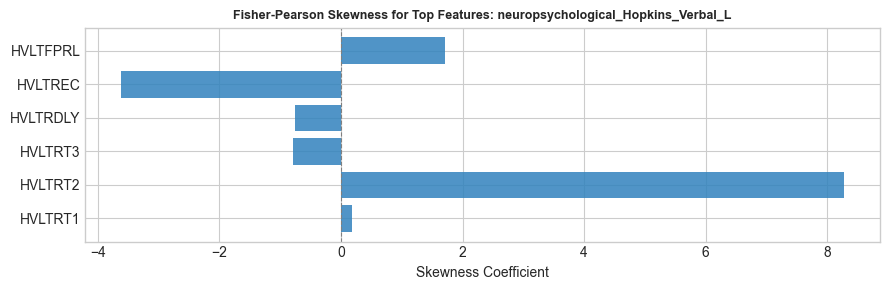

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Hopkins_Verbal_L", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `7` continuous analytical measurements
- **Excluded Features**: `14` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `50.2%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,679 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,015


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,50.17%,50.17%
1,PC2,18.81%,68.98%
2,PC3,9.69%,78.66%
3,PC4,8.04%,86.70%
4,PC5,6.41%,93.11%



Top PC1 Feature Loadings:


,feature_name,loading
0,HVLTRDLY,0.4706
1,HVLTRT2,0.4672
2,HVLTRT3,0.4589
3,HVLTRT1,0.4153
4,HVLTREC,0.3439


Scree & Eigenvector Loadings Plot:


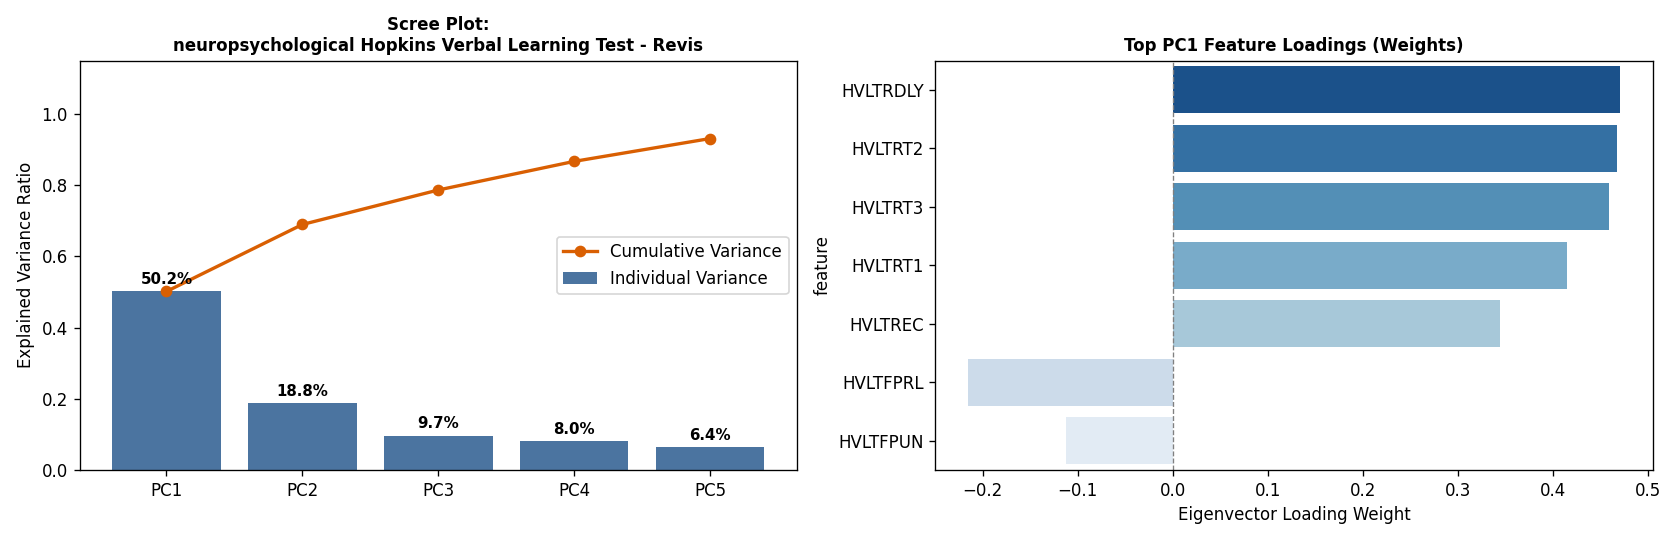

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


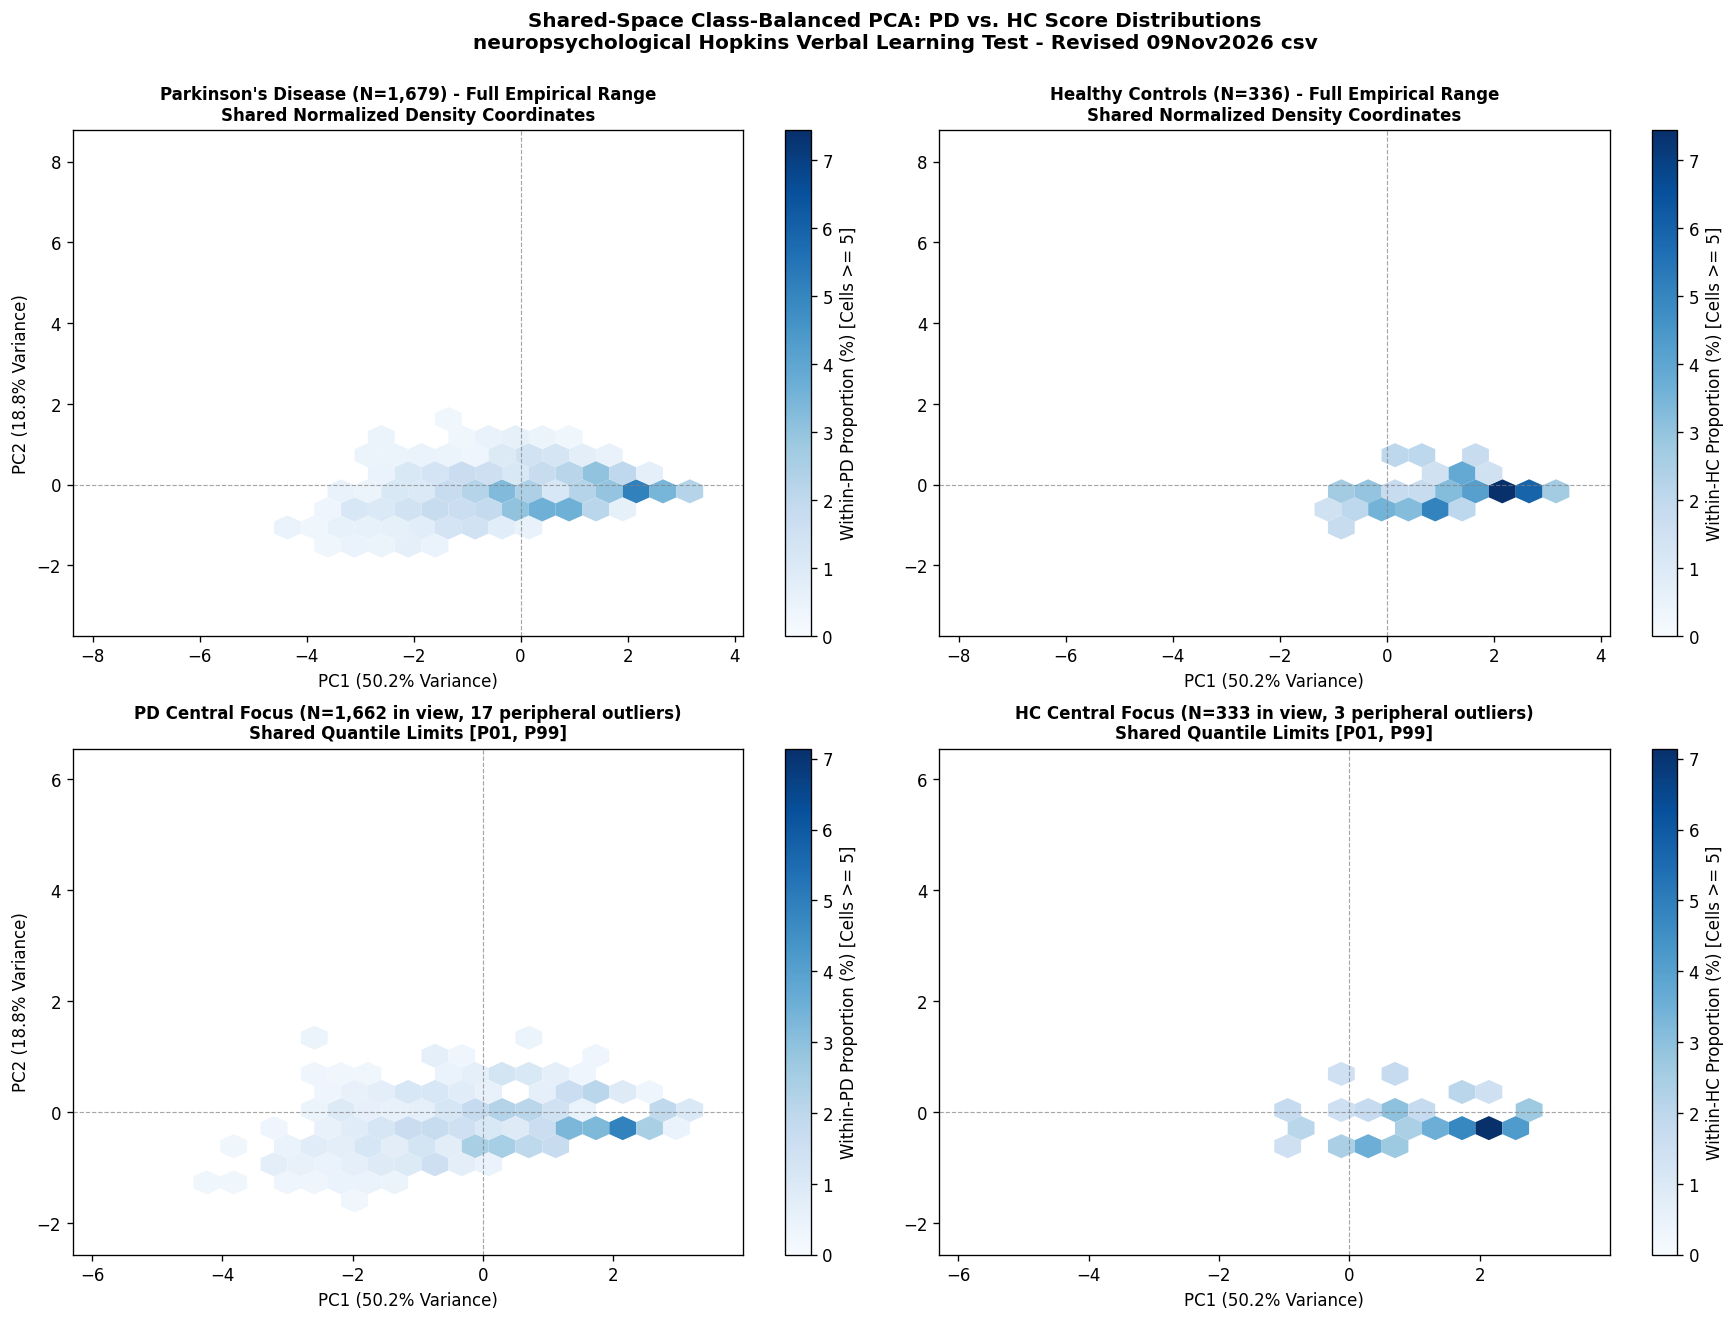

In [8]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Hopkins_Verbal_Learning_Test_-_Revised_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.4. Unit: `Benton_Judgement_of_Line_Orientation_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv`
- **Source Path**: `neuropsychological/Benton_Judgement_of_Line_Orientation_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `BJLO evaluates parietal lobe integrity and spatial orientation by measuring angular matching of lines.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: neuropsychological/Benton_Judgement_of_Line_Orientation_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,335 analyzed rows x 44 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,485 (5,325 participants)
  - PD Retained:  8,129 rows (1,678 participants)
  - HC Retained:  2,206 rows (335 participants)
  - Non-Target Excluded: 9,816 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  334 rows

Exact Variable Schema & Storage Types (44 columns):
Showing first 20 of 44 columns (complete schema committed to neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,335",Identifier
1,PATNO,int64,0,0.0%,"2,013",Identifier
2,EVENT_ID,object,0,0.0%,23,Identifier
3,PAG_NAME,object,0,0.0%,3,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,BENTONVERSION,int64,0,0.0%,2,Instrument Version
6,BJLOT1,float64,"4,758",46.0%,2,Analytical Numeric Measurement
7,BJLOT2,float64,"5,588",54.1%,2,Analytical Numeric Measurement
8,BJLOT3,float64,"4,758",46.0%,2,Analytical Numeric Measurement
9,BJLOT4,float64,"5,588",54.1%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,34
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Instrument Version,1
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 155,342 / 454,740 (34.16%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (35 total, top 8):


,name,missing_count,missing_percent,variable_role
19,BJLOT14,"5,589",54.1%,Analytical Numeric Measurement
23,BJLOT18,"5,589",54.1%,Analytical Numeric Measurement
21,BJLOT16,"5,589",54.1%,Analytical Numeric Measurement
33,BJLOT28,"5,589",54.1%,Analytical Numeric Measurement
35,BJLOT30,"5,589",54.1%,Analytical Numeric Measurement
27,BJLOT22,"5,589",54.1%,Analytical Numeric Measurement
17,BJLOT12,"5,589",54.1%,Analytical Numeric Measurement
29,BJLOT24,"5,589",54.1%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,129"
1,HC,"2,206"



Numeric Summaries & Outlier Diagnostics (36 continuous/discrete features):
Showing top 10 of 36 features (full distribution profiles in neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,BENTONVERSION,1.460,0.498,1.0,1.0,2.0,0.162,Approximately symmetric,0,0
1,BJLOT1,0.820,0.384,0.0,1.0,1.0,-1.669,Strongly skewed (negative),"1,002",0
2,BJLOT2,0.978,0.146,0.0,1.0,1.0,-6.568,Strongly skewed (negative),103,103
3,BJLOT3,0.962,0.191,0.0,1.0,1.0,-4.833,Strongly skewed (negative),212,212
4,BJLOT4,0.957,0.203,0.0,1.0,1.0,-4.509,Strongly skewed (negative),204,204
5,BJLOT5,0.906,0.292,0.0,1.0,1.0,-2.780,Strongly skewed (negative),525,525
6,BJLOT6,0.967,0.179,0.0,1.0,1.0,-5.224,Strongly skewed (negative),157,157
7,BJLOT7,0.880,0.325,0.0,1.0,1.0,-2.340,Strongly skewed (negative),669,0
8,BJLOT8,0.936,0.244,0.0,1.0,1.0,-3.570,Strongly skewed (negative),303,303
9,BJLOT9,0.884,0.320,0.0,1.0,1.0,-2.399,Strongly skewed (negative),647,0


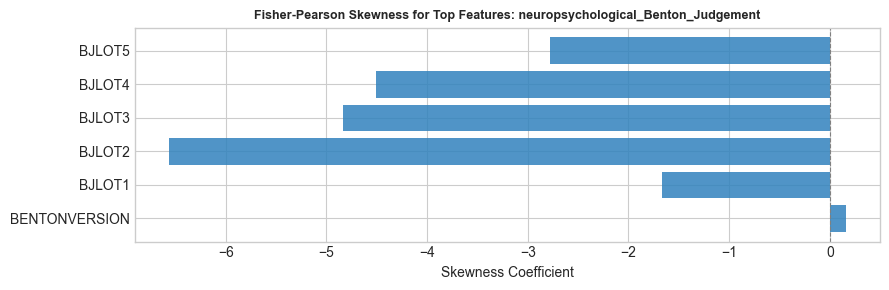

In [9]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Benton_Judgement_of_Line_Orientation_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Benton_Judgement_of_Line_Orientation_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Benton_Judgement", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (1 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [10]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (1 < 2)
Features Evaluated: 1 included, 43 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,BENTONVERSION,"Identifier, date, visit, demographic, instrume..."
6,BJLOT1,Excessive missingness (46.0% > 40%)
7,BJLOT2,Excessive missingness (54.1% > 40%)
8,BJLOT3,Excessive missingness (46.0% > 40%)
9,BJLOT4,Excessive missingness (54.1% > 40%)


---
## 2.5. Unit: `Letter_-_Number_Sequencing_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv`
- **Source Path**: `neuropsychological/Letter_-_Number_Sequencing_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Working memory test requiring mental re-ordering of intermixed letters and numbers in ascending and alphabetical order.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Letter_-_Number_Sequencing_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 10,345 analyzed rows x 32 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,492 (5,326 participants)
  - PD Retained:  8,140 rows (1,678 participants)
  - HC Retained:  2,205 rows (336 participants)
  - Non-Target Excluded: 9,816 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  331 rows

Exact Variable Schema & Storage Types (32 columns):
Showing first 20 of 32 columns (complete schema committed to neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,345",Identifier
1,PATNO,int64,0,0.0%,"2,014",Identifier
2,EVENT_ID,object,0,0.0%,23,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,LNS1A,float64,0,0.0%,2,Analytical Numeric Measurement
6,LNS1B,float64,1,0.0%,2,Analytical Numeric Measurement
7,LNS1C,float64,3,0.0%,2,Analytical Numeric Measurement
8,LNS2A,float64,16,0.1%,2,Analytical Numeric Measurement
9,LNS2B,float64,17,0.2%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,23
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 38,411 / 331,040 (11.60%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (20 total, top 8):


,name,missing_count,missing_percent,variable_role
24,LNS7B,"5,990",57.9%,Analytical Numeric Measurement
25,LNS7C,"5,990",57.9%,Analytical Numeric Measurement
23,LNS7A,"5,989",57.9%,Analytical Numeric Measurement
22,LNS6C,"4,276",41.3%,Analytical Numeric Measurement
21,LNS6B,"4,272",41.3%,Analytical Numeric Measurement
20,LNS6A,"4,265",41.2%,Analytical Numeric Measurement
19,LNS5C,"1,968",19.0%,Analytical Numeric Measurement
18,LNS5B,"1,964",19.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,140"
1,HC,"2,205"



Numeric Summaries & Outlier Diagnostics (24 continuous/discrete features):
Showing top 10 of 24 features (full distribution profiles in neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,LNS1A,0.991,0.092,0.0,1.0,1.0,-10.705,Strongly skewed (negative),88,88
1,LNS1B,0.975,0.157,0.0,1.0,1.0,-6.068,Strongly skewed (negative),260,260
2,LNS1C,0.979,0.143,0.0,1.0,1.0,-6.702,Strongly skewed (negative),216,216
3,LNS2A,0.939,0.240,0.0,1.0,1.0,-3.659,Strongly skewed (negative),633,633
4,LNS2B,0.911,0.285,0.0,1.0,1.0,-2.879,Strongly skewed (negative),923,923
5,LNS2C,0.953,0.212,0.0,1.0,1.0,-4.269,Strongly skewed (negative),488,488
6,LNS3A,0.773,0.419,0.0,1.0,1.0,-1.304,Strongly skewed (negative),"2,323",0
7,LNS3B,0.777,0.416,0.0,1.0,1.0,-1.333,Strongly skewed (negative),"2,279",0
8,LNS3C,0.814,0.389,0.0,1.0,1.0,-1.614,Strongly skewed (negative),"1,903",0
9,LNS4A,0.438,0.496,0.0,0.0,1.0,0.251,Approximately symmetric,0,0


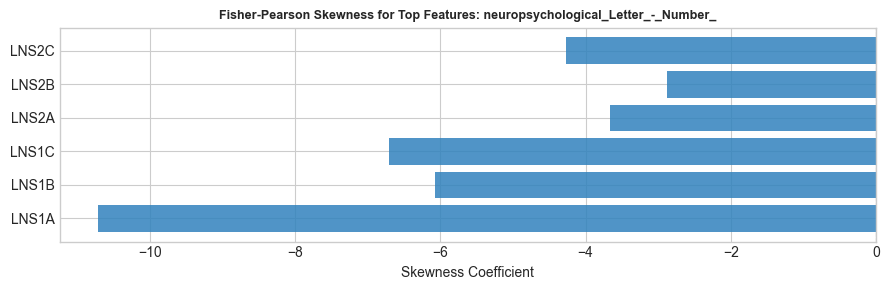

In [11]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Letter_-_Number_Sequencing_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Letter_-_Number_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `15` continuous analytical measurements
- **Excluded Features**: `17` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `20.3%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,678 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,014


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,20.30%,20.30%
1,PC2,11.48%,31.79%
2,PC3,7.71%,39.50%
3,PC4,6.88%,46.38%
4,PC5,6.33%,52.71%



Top PC1 Feature Loadings:


,feature_name,loading
0,LNS4B,0.3289
1,LNS4A,0.3164
2,LNS5C,0.3102
3,LNS2C,0.3068
4,LNS5A,0.2809


Scree & Eigenvector Loadings Plot:


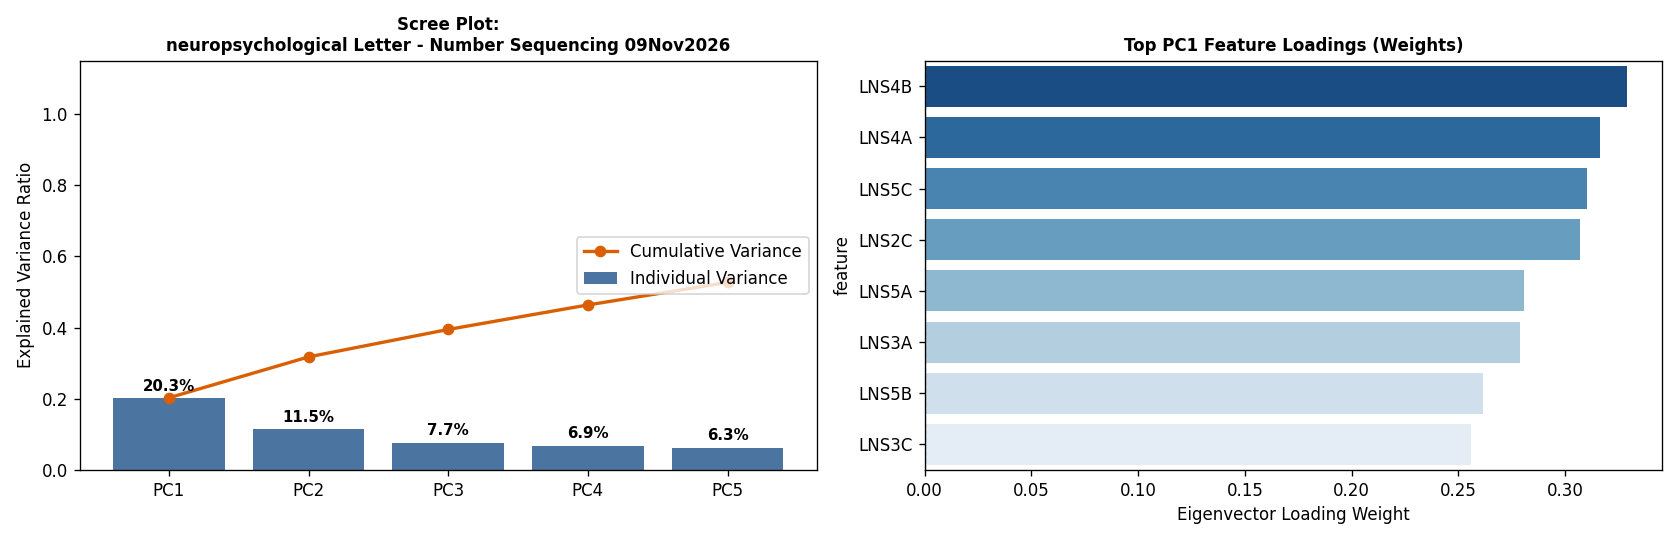

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


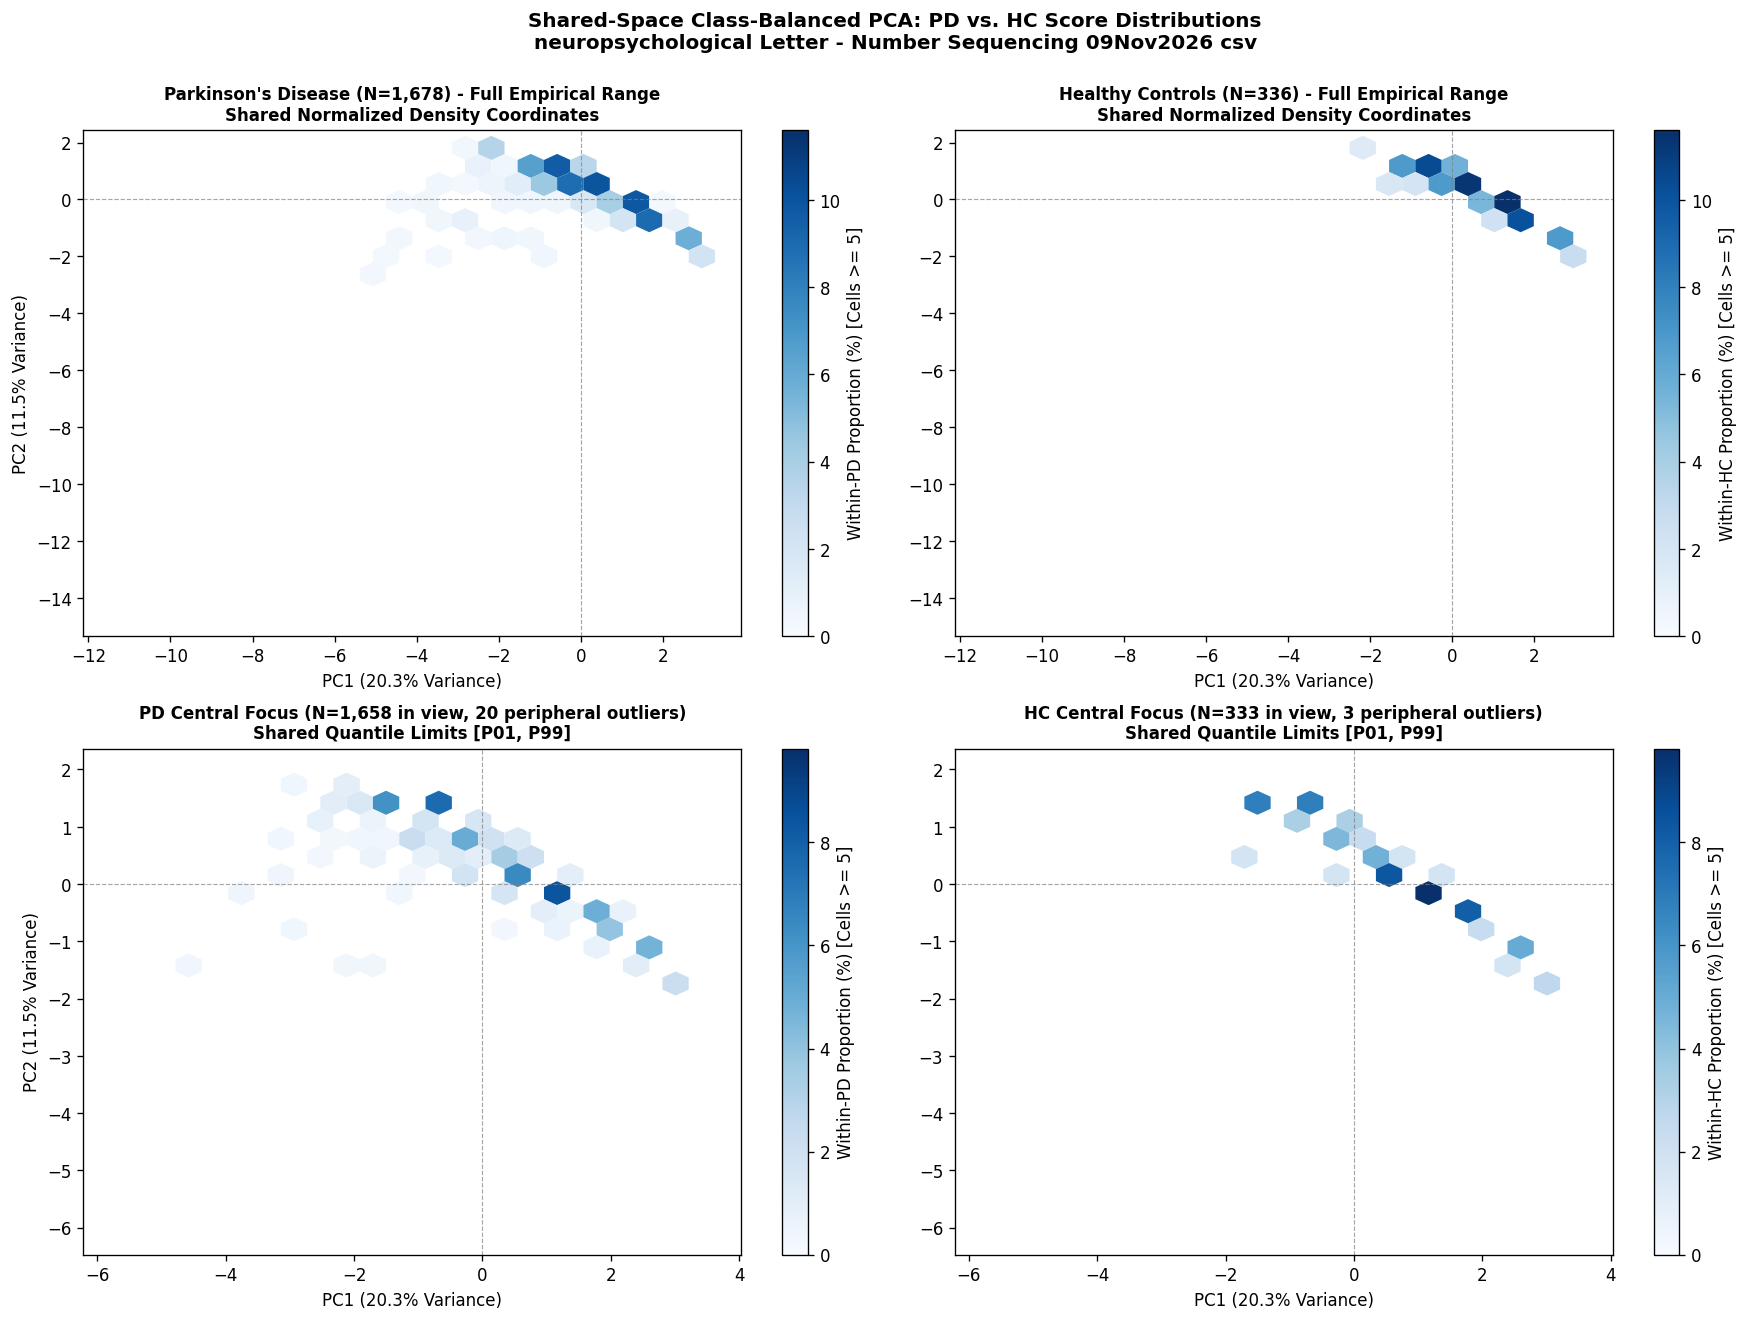

In [12]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Letter_-_Number_Sequencing_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.6. Unit: `Cognitive_Categorization_09Nov2026.csv` 
- **Unit Slug**: `other_cognitive_Cognitive_Categorization_09Nov2026_csv`
- **Source Path**: `other cognitive/Cognitive_Categorization_09Nov2026.csv`
- **Committed Unit Artifact**: [`other_cognitive_Cognitive_Categorization_09Nov2026_csv.json`](../EDA/outputs/reports/units/other_cognitive_Cognitive_Categorization_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Formal clinical diagnosis of cognitive decline stage (`1 = Normal Cognition`, `2 = MCI`, `3 = Dementia`).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: other cognitive/Cognitive_Categorization_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,534 analyzed rows x 16 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 21,344 (5,287 participants)
  - PD Retained:  8,552 rows (1,664 participants)
  - HC Retained:  1,982 rows (323 participants)
  - Non-Target Excluded: 10,481 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  329 rows

Exact Variable Schema & Storage Types (16 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,534",Identifier
1,PATNO,int64,0,0.0%,"1,987",Identifier
2,EVENT_ID,object,0,0.0%,25,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,INFODT,object,0,0.0%,172,Date / Timestamp / Visit
5,PTCGBOTH,float64,2,0.0%,3,Analytical Numeric Measurement
6,COGDECLN,float64,3,0.0%,2,Analytical Numeric Measurement
7,FNCDTCOG,float64,4,0.0%,2,Date / Timestamp / Visit
8,COGSTATE,float64,4,0.0%,3,Diagnostic / Categorical Code
9,COGDXCL,float64,4,0.0%,4,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,5
Date / Timestamp / Visit,3
Identifier,3
Administrative Metadata,2
Diagnostic / Categorical Code,1
Categorical / Text,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 12,430 / 168,544 (7.37%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (8 total, top 8):


,name,missing_count,missing_percent,variable_role
11,COGCAT,"6,205",58.9%,Analytical Numeric Measurement
12,COGCAT_TEXT,"6,205",58.9%,Categorical / Text
8,COGSTATE,4,0.0%,Diagnostic / Categorical Code
7,FNCDTCOG,4,0.0%,Date / Timestamp / Visit
9,COGDXCL,4,0.0%,Analytical Numeric Measurement
6,COGDECLN,3,0.0%,Analytical Numeric Measurement
10,RVWNPSY,3,0.0%,Analytical Numeric Measurement
5,PTCGBOTH,2,0.0%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,552"
1,HC,"1,982"



Numeric Summaries & Outlier Diagnostics (7 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PTCGBOTH,1.226,0.629,1.0,1.0,3.0,2.445,Strongly skewed (positive),"1,216",0
1,COGDECLN,0.265,0.441,0.0,0.0,1.0,1.066,Strongly skewed (positive),0,0
2,FNCDTCOG,0.060,0.238,0.0,0.0,1.0,3.691,Strongly skewed (positive),636,636
3,COGSTATE,1.204,0.451,1.0,1.0,3.0,2.109,Strongly skewed (positive),"1,938",215
4,COGDXCL,1.261,0.473,1.0,1.0,4.0,1.551,Strongly skewed (positive),"2,597",147
5,RVWNPSY,0.252,0.434,0.0,0.0,1.0,1.142,Strongly skewed (positive),0,0
6,COGCAT,1.733,1.317,1.0,1.0,5.0,1.685,Strongly skewed (positive),582,0


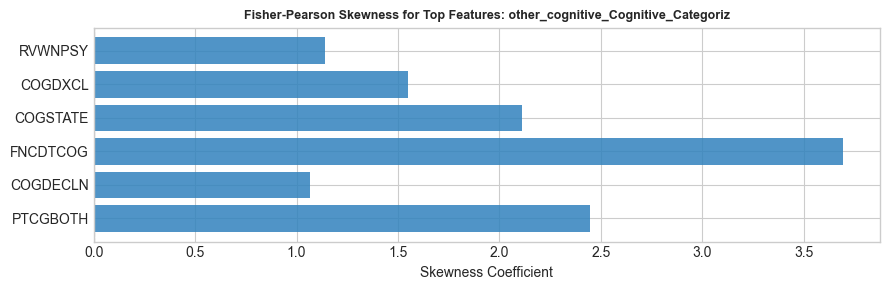

In [13]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "other_cognitive_Cognitive_Categorization_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: other cognitive/Cognitive_Categorization_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to other_cognitive_Cognitive_Categorization_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in other_cognitive_Cognitive_Categorization_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: other_cognitive_Cognitive_Categoriz", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [14]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 16 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,PTCGBOTH,"Identifier, date, visit, demographic, instrume..."
6,COGDECLN,"Identifier, date, visit, demographic, instrume..."
7,FNCDTCOG,"Identifier, date, visit, demographic, instrume..."
8,COGSTATE,"Identifier, date, visit, demographic, instrume..."
9,COGDXCL,"Identifier, date, visit, demographic, instrume..."


---
## 2.7. Unit: `Modified_Semantic_Fluency_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv`
- **Source Path**: `neuropsychological/Modified_Semantic_Fluency_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Semantic category generation (animals, fruits, vegetables) probing temporal-frontal lexical networks.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: neuropsychological/Modified_Semantic_Fluency_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,379 analyzed rows x 14 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,548 (5,331 participants)
  - PD Retained:  8,173 rows (1,679 participants)
  - HC Retained:  2,206 rows (336 participants)
  - Non-Target Excluded: 9,834 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  335 rows

Exact Variable Schema & Storage Types (14 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,379",Identifier
1,PATNO,int64,0,0.0%,"2,015",Identifier
2,EVENT_ID,object,0,0.0%,23,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,VLTANIM,float64,0,0.0%,45,Analytical Numeric Measurement
6,VLTVEG,float64,"5,729",55.2%,34,Analytical Numeric Measurement
7,VLTFRUIT,float64,"5,729",55.2%,31,Analytical Numeric Measurement
8,AGE_ASSESS_SFTANIM,int64,0,0.0%,70,Demographic / Covariate
9,DVS_SFTANIM,float64,0,0.0%,19,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,5
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 11,474 / 145,306 (7.90%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (3 total, top 8):


,name,missing_count,missing_percent,variable_role
6,VLTVEG,"5,729",55.2%,Analytical Numeric Measurement
7,VLTFRUIT,"5,729",55.2%,Analytical Numeric Measurement
10,DVT_SFTANIM,16,0.1%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"8,173"
1,HC,"2,206"



Numeric Summaries & Outlier Diagnostics (6 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,VLTANIM,20.990,5.841,0.0,21.0,45.0,0.163,Approximately symmetric,83,53
1,VLTVEG,14.206,4.523,0.0,14.0,40.0,0.286,Approximately symmetric,36,22
2,VLTFRUIT,13.970,4.476,0.0,14.0,30.0,0.274,Approximately symmetric,40,16
3,AGE_ASSESS_SFTANIM,65.040,10.140,29.0,66.0,98.0,-0.513,Moderately skewed (negative),186,67
4,DVS_SFTANIM,10.662,3.301,1.0,11.0,19.0,-0.171,Approximately symmetric,226,0
5,DVT_SFTANIM,51.411,11.294,8.0,51.0,88.0,-0.154,Approximately symmetric,389,56


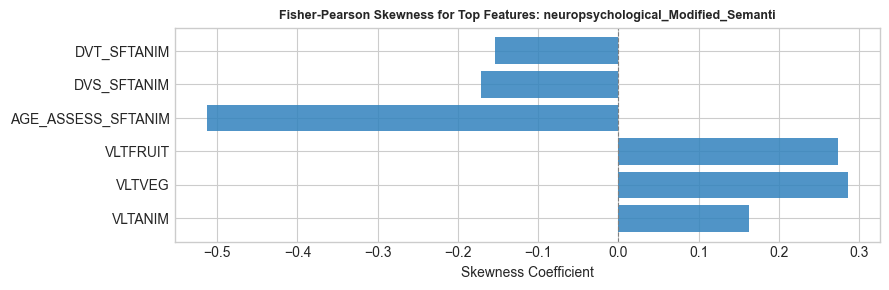

In [15]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Modified_Semantic_Fluency_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Modified_Semantic_Fluency_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Modified_Semanti", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (1 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [16]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (1 < 2)
Features Evaluated: 1 included, 13 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,VLTVEG,Excessive missingness (55.2% > 40%)
6,VLTFRUIT,Excessive missingness (55.2% > 40%)
7,AGE_ASSESS_SFTANIM,"Identifier, date, visit, demographic, instrume..."
8,ORIG_ENTRY,"Identifier, date, visit, demographic, instrume..."
9,LAST_UPDATE,"Identifier, date, visit, demographic, instrume..."


---
## 2.8. Unit: `Lexical_Fluency_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Lexical_Fluency_09Nov2026_csv`
- **Source Path**: `neuropsychological/Lexical_Fluency_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Lexical_Fluency_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Lexical_Fluency_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Phonemic fluency test (F-A-S words in 60 seconds) assessing frontal lobe executive retrieval.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Lexical_Fluency_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 5,736 analyzed rows x 14 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 14,020 (4,796 participants)
  - PD Retained:  4,662 rows (1,421 participants)
  - HC Retained:  1,074 rows (256 participants)
  - Non-Target Excluded: 7,964 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  320 rows

Exact Variable Schema & Storage Types (14 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"5,736",Identifier
1,PATNO,int64,0,0.0%,"1,677",Identifier
2,EVENT_ID,object,0,0.0%,17,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,92,Date / Timestamp / Visit
5,LXFLUEF,float64,7,0.1%,41,Analytical Numeric Measurement
6,LXFLUEA,float64,4,0.1%,36,Analytical Numeric Measurement
7,LXFLUES,float64,7,0.1%,40,Analytical Numeric Measurement
8,AGE_ASSESS_FAS,float64,430,7.5%,70,Demographic / Covariate
9,DVS_FAS,float64,444,7.7%,18,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,5
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 1,352 / 80,304 (1.68%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (6 total, top 8):


,name,missing_count,missing_percent,variable_role
10,DVT_FAS,460,8.0%,Analytical Numeric Measurement
9,DVS_FAS,444,7.7%,Analytical Numeric Measurement
8,AGE_ASSESS_FAS,430,7.5%,Demographic / Covariate
5,LXFLUEF,7,0.1%,Analytical Numeric Measurement
7,LXFLUES,7,0.1%,Analytical Numeric Measurement
6,LXFLUEA,4,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"4,662"
1,HC,"1,074"



Numeric Summaries & Outlier Diagnostics (6 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,LXFLUEF,14.954,5.262,0.0,15.0,42.0,0.392,Approximately symmetric,64,37
1,LXFLUEA,13.162,5.027,0.0,13.0,38.0,0.302,Approximately symmetric,74,14
2,LXFLUES,15.460,5.555,0.0,15.0,40.0,0.276,Approximately symmetric,65,17
3,AGE_ASSESS_FAS,66.333,9.787,29.0,67.0,98.0,-0.537,Moderately skewed (negative),110,41
4,DVS_FAS,11.049,3.361,2.0,11.0,19.0,-0.030,Approximately symmetric,61,0
5,DVT_FAS,51.438,11.533,15.0,51.0,86.0,0.048,Approximately symmetric,45,5


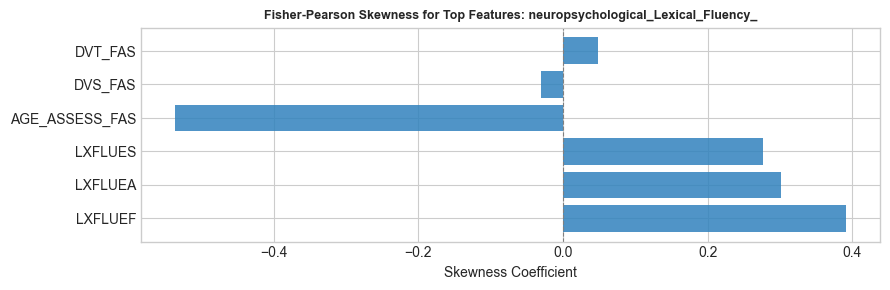

In [17]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Lexical_Fluency_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Lexical_Fluency_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Lexical_Fluency_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Lexical_Fluency_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Lexical_Fluency_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `3` continuous analytical measurements
- **Excluded Features**: `11` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `78.1%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,421 participants
  - Initial Eligible HC: 256 participants
  - Class-Balanced Fit Size: 256 participants per class (Total Fit N=512)
  - Total Projected Participants: 1,677


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,78.08%,78.08%
1,PC2,11.58%,89.67%
2,PC3,10.33%,100.00%



Top PC1 Feature Loadings:


,feature_name,loading
0,LXFLUES,0.5821
1,LXFLUEA,0.5771
2,LXFLUEF,0.5728


Scree & Eigenvector Loadings Plot:


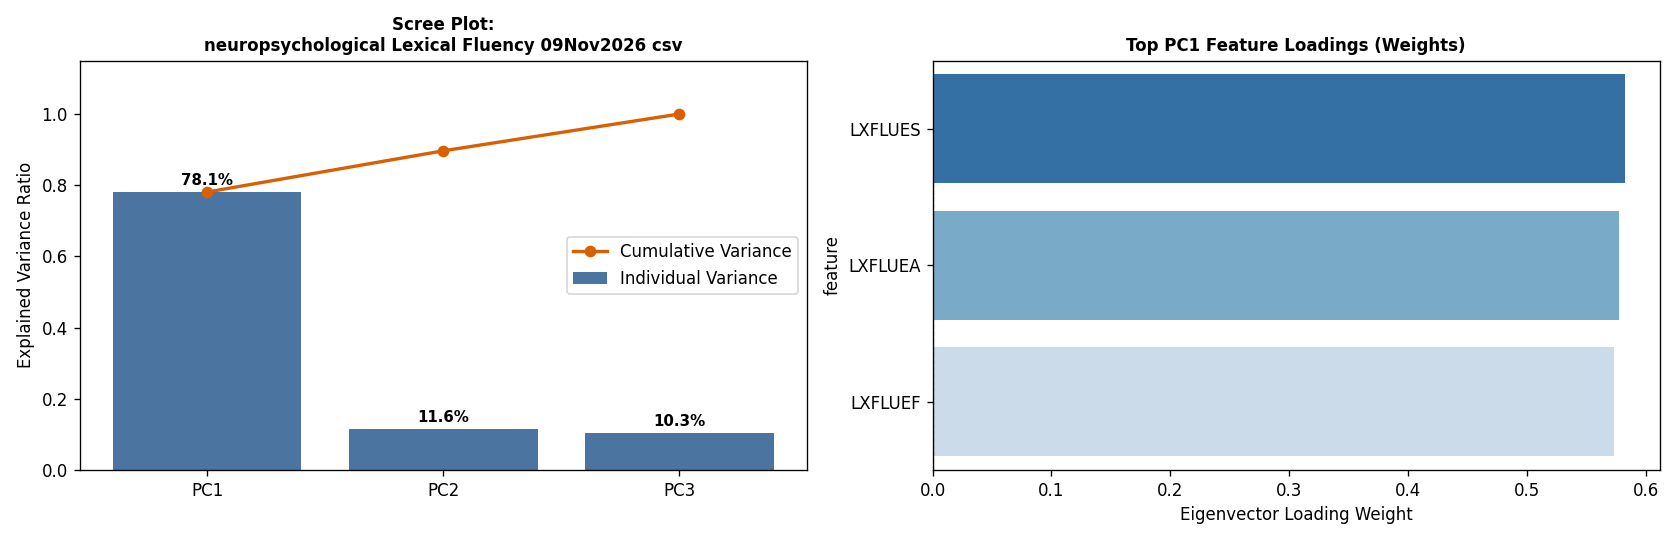

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


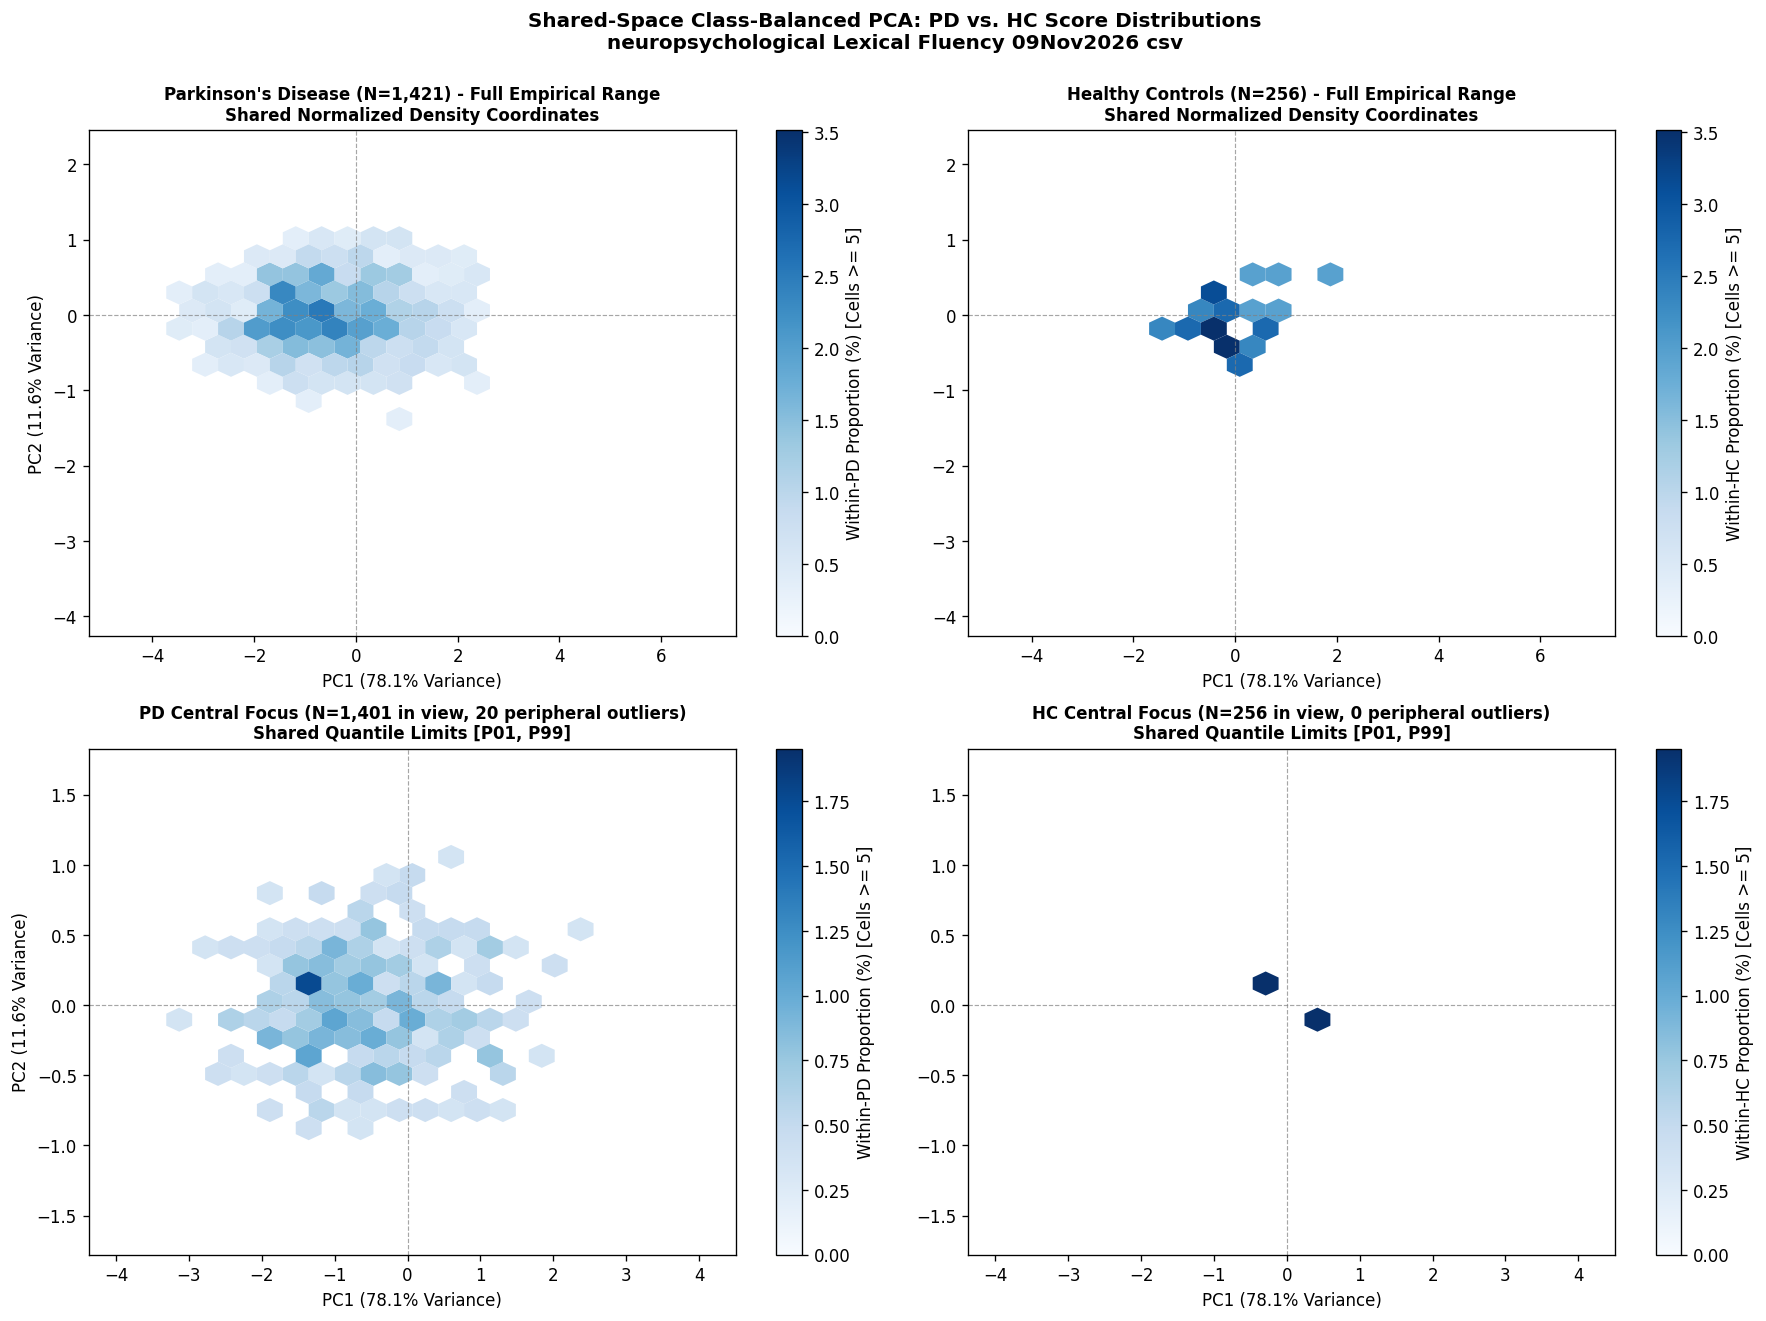

In [18]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Lexical_Fluency_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Lexical_Fluency_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.9. Unit: `Clock_Drawing_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Clock_Drawing_09Nov2026_csv`
- **Source Path**: `neuropsychological/Clock_Drawing_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Clock_Drawing_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Clock_Drawing_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Visuoconstructive and executive function task evaluating clock face construction and hand placement.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Clock_Drawing_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 5,786 analyzed rows x 19 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 14,368 (5,031 participants)
  - PD Retained:  4,717 rows (1,423 participants)
  - HC Retained:  1,069 rows (255 participants)
  - Non-Target Excluded: 8,026 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  556 rows

Exact Variable Schema & Storage Types (19 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"5,786",Identifier
1,PATNO,int64,0,0.0%,"1,678",Identifier
2,EVENT_ID,object,0,0.0%,18,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,94,Date / Timestamp / Visit
5,CLCKPII,float64,1,0.0%,2,Analytical Numeric Measurement
6,CLCK2HND,float64,1,0.0%,2,Analytical Numeric Measurement
7,CLCKNMRK,float64,1,0.0%,2,Analytical Numeric Measurement
8,CLCKNUIN,float64,4,0.1%,2,Analytical Numeric Measurement
9,CLCKALNU,float64,1,0.0%,2,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,10
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 1,166 / 109,934 (1.06%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (11 total, top 8):


,name,missing_count,missing_percent,variable_role
14,DVT_CLCKDRAW,385,6.7%,Analytical Numeric Measurement
15,DVZ_CLCKDRAW,385,6.7%,Analytical Numeric Measurement
13,AGE_ASSESS_CLCKDRAW,384,6.6%,Demographic / Covariate
8,CLCKNUIN,4,0.1%,Analytical Numeric Measurement
10,CLCKNUSP,2,0.0%,Analytical Numeric Measurement
5,CLCKPII,1,0.0%,Analytical Numeric Measurement
6,CLCK2HND,1,0.0%,Analytical Numeric Measurement
7,CLCKNMRK,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"4,717"
1,HC,"1,069"



Numeric Summaries & Outlier Diagnostics (11 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,CLCKPII,0.910,0.286,0.00,1.00,1.00,-2.872,Strongly skewed (negative),519,519
1,CLCK2HND,0.945,0.229,0.00,1.00,1.00,-3.884,Strongly skewed (negative),321,321
2,CLCKNMRK,0.831,0.375,0.00,1.00,1.00,-1.770,Strongly skewed (negative),976,0
3,CLCKNUIN,0.782,0.413,0.00,1.00,1.00,-1.363,Strongly skewed (negative),"1,263",0
4,CLCKALNU,0.909,0.287,0.00,1.00,1.00,-2.854,Strongly skewed (negative),524,524
5,CLCKNUSP,0.845,0.362,0.00,1.00,1.00,-1.912,Strongly skewed (negative),894,0
6,CLCKNUED,0.808,0.394,0.00,1.00,1.00,-1.563,Strongly skewed (negative),"1,112",0
7,CLCKTOT,6.029,1.481,0.00,7.00,7.00,-1.966,Strongly skewed (negative),731,140
8,AGE_ASSESS_CLCKDRAW,66.321,9.801,29.00,67.00,98.00,-0.537,Moderately skewed (negative),111,42
9,DVT_CLCKDRAW,61.811,17.130,-1.00,73.00,76.00,-1.694,Strongly skewed (negative),688,80


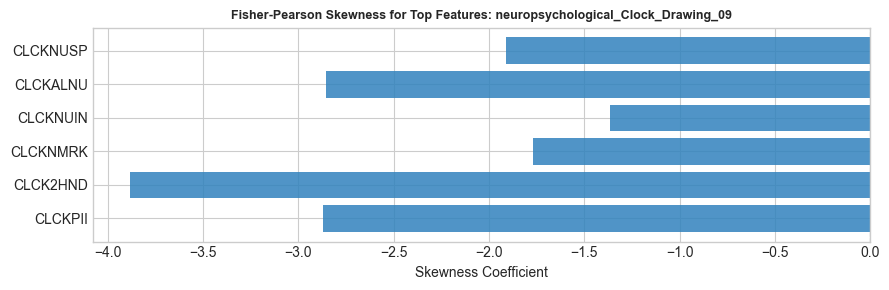

In [19]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Clock_Drawing_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Clock_Drawing_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Clock_Drawing_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Clock_Drawing_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Clock_Drawing_09", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `7` continuous analytical measurements
- **Excluded Features**: `12` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `34.9%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,423 participants
  - Initial Eligible HC: 255 participants
  - Class-Balanced Fit Size: 255 participants per class (Total Fit N=510)
  - Total Projected Participants: 1,678


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,34.91%,34.91%
1,PC2,15.54%,50.44%
2,PC3,12.52%,62.96%
3,PC4,12.27%,75.24%
4,PC5,10.02%,85.26%



Top PC1 Feature Loadings:


,feature_name,loading
0,CLCKALNU,0.4178
1,CLCKPII,0.4086
2,CLCKNMRK,0.3956
3,CLCKNUED,0.3897
4,CLCKNUSP,0.3668


Scree & Eigenvector Loadings Plot:


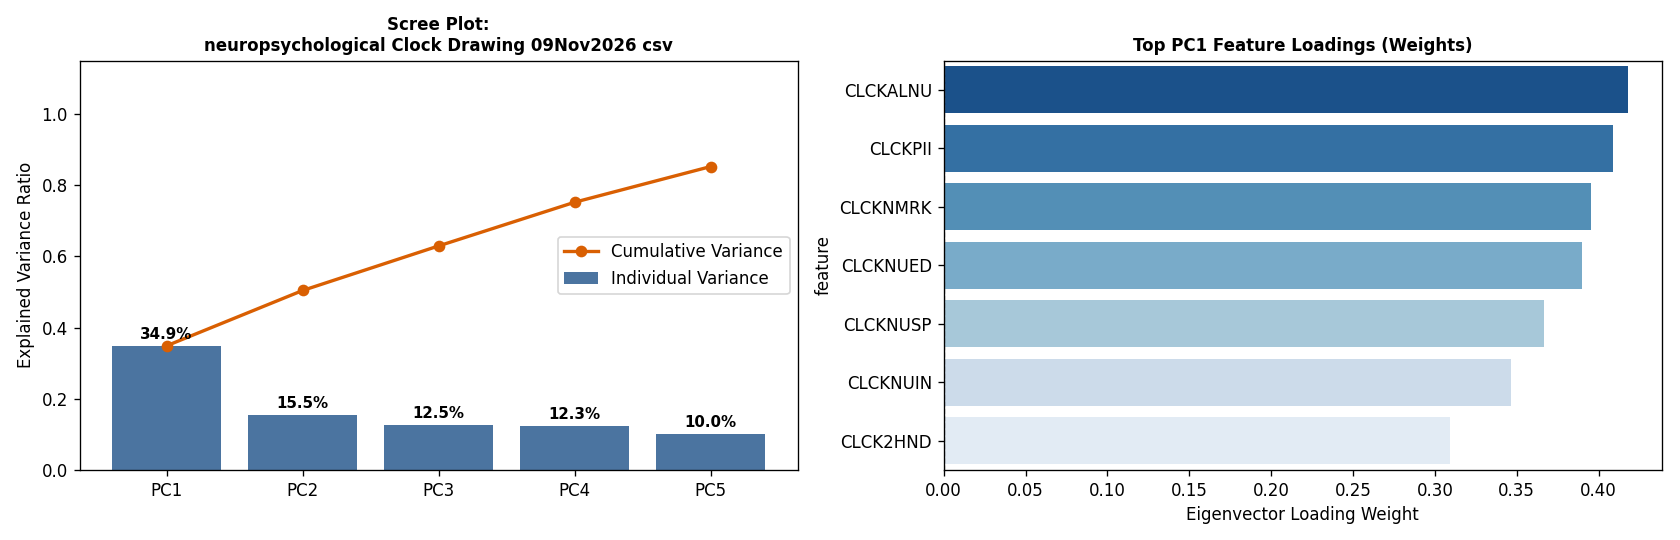

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


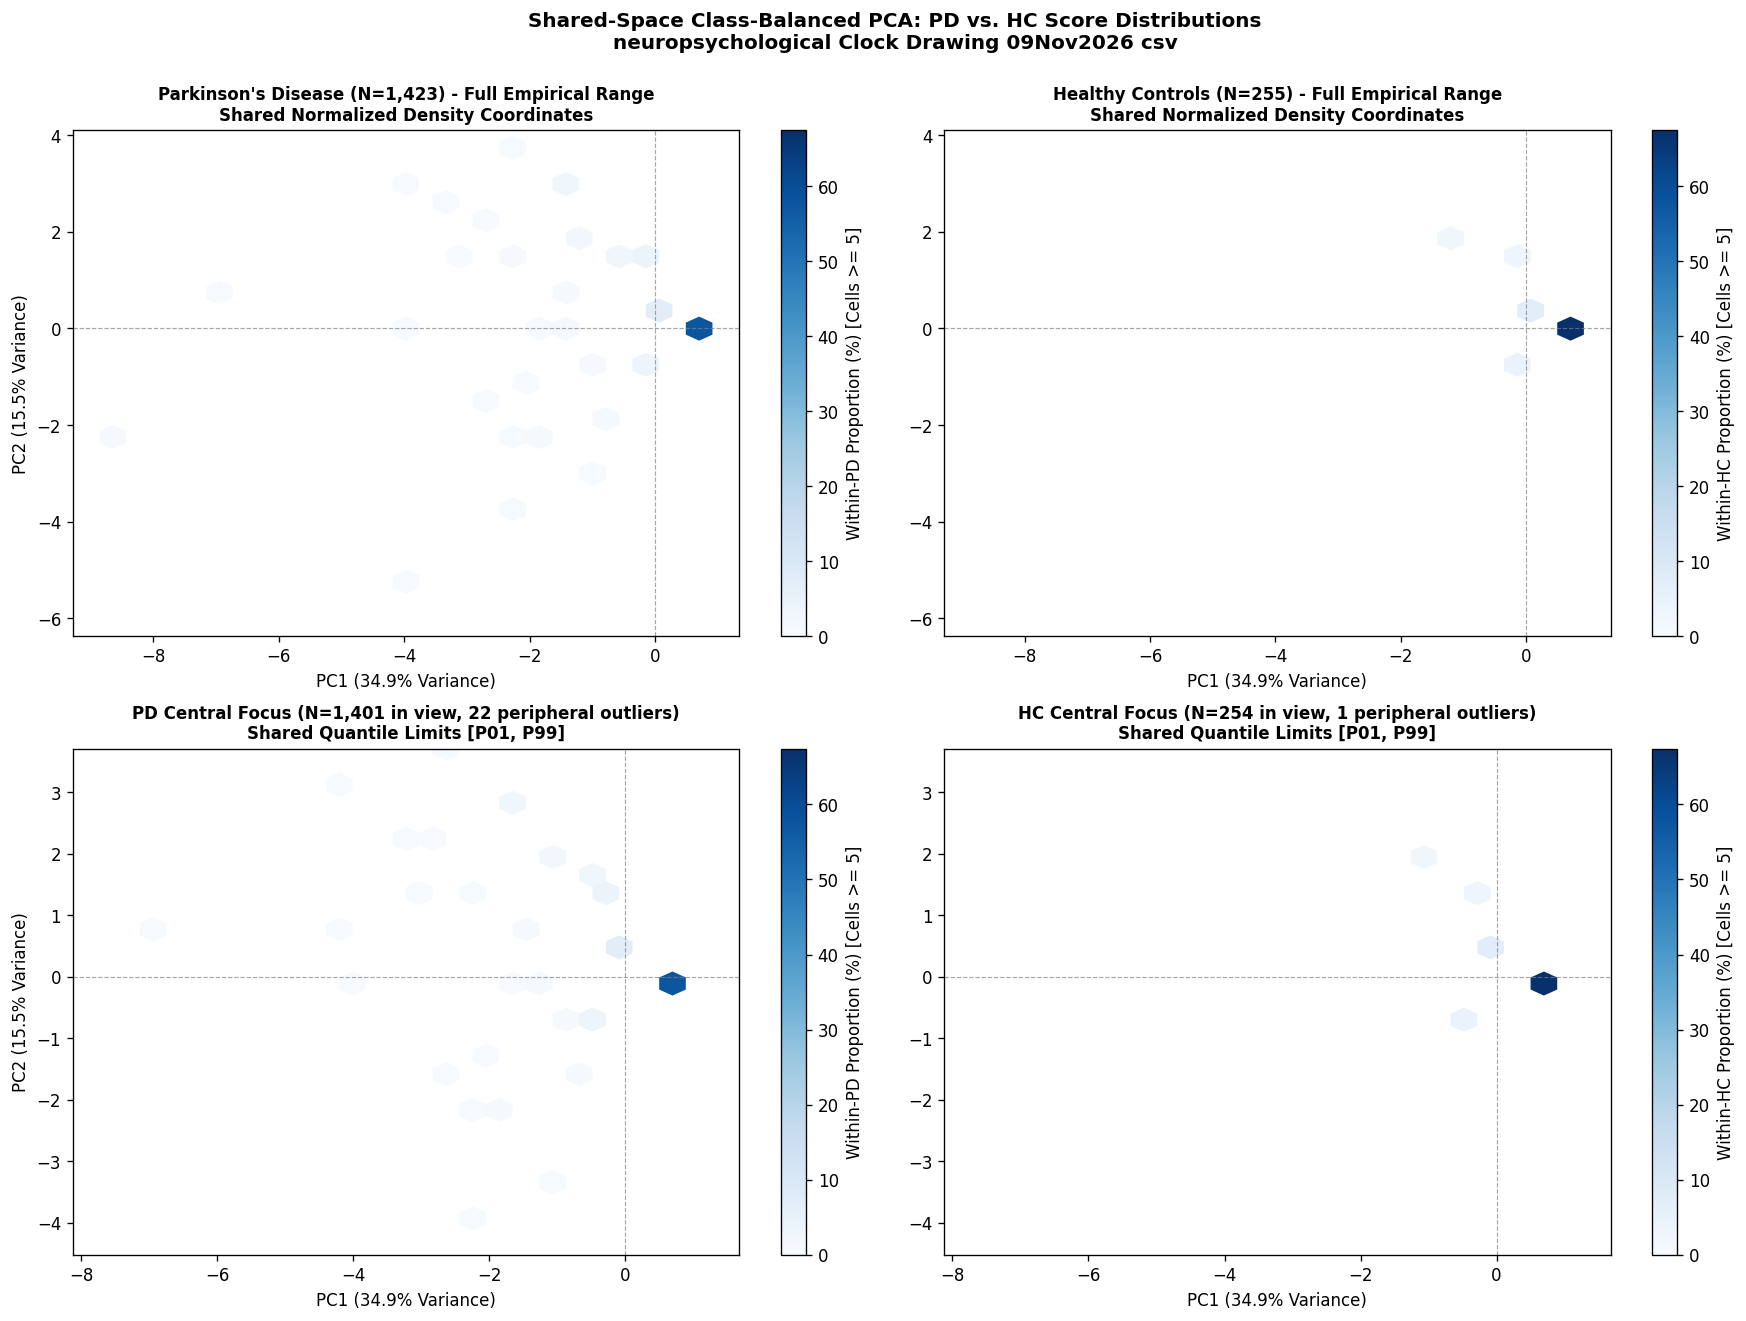

In [20]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Clock_Drawing_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Clock_Drawing_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.10. Unit: `Trail_Making_A_and_B_09Nov2026.csv` 
- **Unit Slug**: `neuropsychological_Trail_Making_A_and_B_09Nov2026_csv`
- **Source Path**: `neuropsychological/Trail_Making_A_and_B_09Nov2026.csv`
- **Committed Unit Artifact**: [`neuropsychological_Trail_Making_A_and_B_09Nov2026_csv.json`](../EDA/outputs/reports/units/neuropsychological_Trail_Making_A_and_B_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `TMT Part A measures psychomotor speed; Part B measures cognitive flexibility, visual search, and mental task switching.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: neuropsychological/Trail_Making_A_and_B_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 5,709 analyzed rows x 17 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 13,966 (4,788 participants)
  - PD Retained:  4,635 rows (1,417 participants)
  - HC Retained:  1,074 rows (256 participants)
  - Non-Target Excluded: 7,940 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  317 rows

Exact Variable Schema & Storage Types (17 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"5,709",Identifier
1,PATNO,int64,0,0.0%,"1,673",Identifier
2,EVENT_ID,object,0,0.0%,17,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,92,Date / Timestamp / Visit
5,TMTACMPL,float64,1,0.0%,2,Analytical Numeric Measurement
6,TMTASEC,float64,75,1.3%,135,Analytical Numeric Measurement
7,TMTACORR,float64,"5,636",98.7%,23,Analytical Numeric Measurement
8,TMTBCMPL,float64,8,0.1%,2,Analytical Numeric Measurement
9,TMTBSEC,float64,319,5.6%,274,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,8
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 12,751 / 97,053 (13.14%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (9 total, top 8):


,name,missing_count,missing_percent,variable_role
7,TMTACORR,"5,636",98.7%,Analytical Numeric Measurement
10,TMTBCORR,"5,403",94.6%,Analytical Numeric Measurement
13,DVZ_TMTB,446,7.8%,Analytical Numeric Measurement
12,DVZ_TMTA,440,7.7%,Analytical Numeric Measurement
11,AGE_ASSESS_TMT,423,7.4%,Demographic / Covariate
9,TMTBSEC,319,5.6%,Analytical Numeric Measurement
6,TMTASEC,75,1.3%,Analytical Numeric Measurement
8,TMTBCMPL,8,0.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"4,635"
1,HC,"1,074"



Numeric Summaries & Outlier Diagnostics (9 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,TMTACMPL,0.987,0.112,0.0,1.00,1.0,-8.737,Strongly skewed (negative),72,72
1,TMTASEC,40.224,20.105,4.0,35.00,150.0,2.086,Strongly skewed (positive),304,129
2,TMTACORR,25.630,49.878,0.0,19.00,360.0,5.372,Strongly skewed (positive),3,3
3,TMTBCMPL,0.946,0.227,0.0,1.00,1.0,-3.931,Strongly skewed (negative),310,310
4,TMTBSEC,91.098,48.727,0.0,78.00,300.0,1.702,Strongly skewed (positive),323,121
5,TMTBCORR,16.585,42.078,0.0,12.50,429.0,8.445,Strongly skewed (positive),4,4
6,AGE_ASSESS_TMT,66.306,9.771,29.0,67.00,98.0,-0.531,Moderately skewed (negative),108,40
7,DVZ_TMTA,-0.173,1.335,-3.0,0.13,3.0,-0.701,Moderately skewed (negative),0,0
8,DVZ_TMTB,-0.424,1.597,-3.0,-0.08,3.0,-0.321,Approximately symmetric,0,0


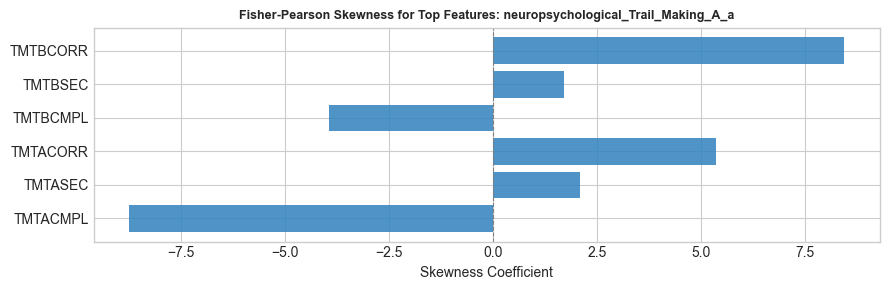

In [21]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "neuropsychological_Trail_Making_A_and_B_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: neuropsychological/Trail_Making_A_and_B_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to neuropsychological_Trail_Making_A_and_B_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in neuropsychological_Trail_Making_A_and_B_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: neuropsychological_Trail_Making_A_a", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `4` continuous analytical measurements
- **Excluded Features**: `13` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `41.2%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,417 participants
  - Initial Eligible HC: 256 participants
  - Class-Balanced Fit Size: 256 participants per class (Total Fit N=512)
  - Total Projected Participants: 1,673


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,41.24%,41.24%
1,PC2,31.51%,72.75%
2,PC3,19.66%,92.41%
3,PC4,7.59%,100.00%



Top PC1 Feature Loadings:


,feature_name,loading
0,TMTASEC,0.6969
1,TMTBSEC,0.5507
2,TMTBCMPL,-0.4284
3,TMTACMPL,-0.1657


Scree & Eigenvector Loadings Plot:


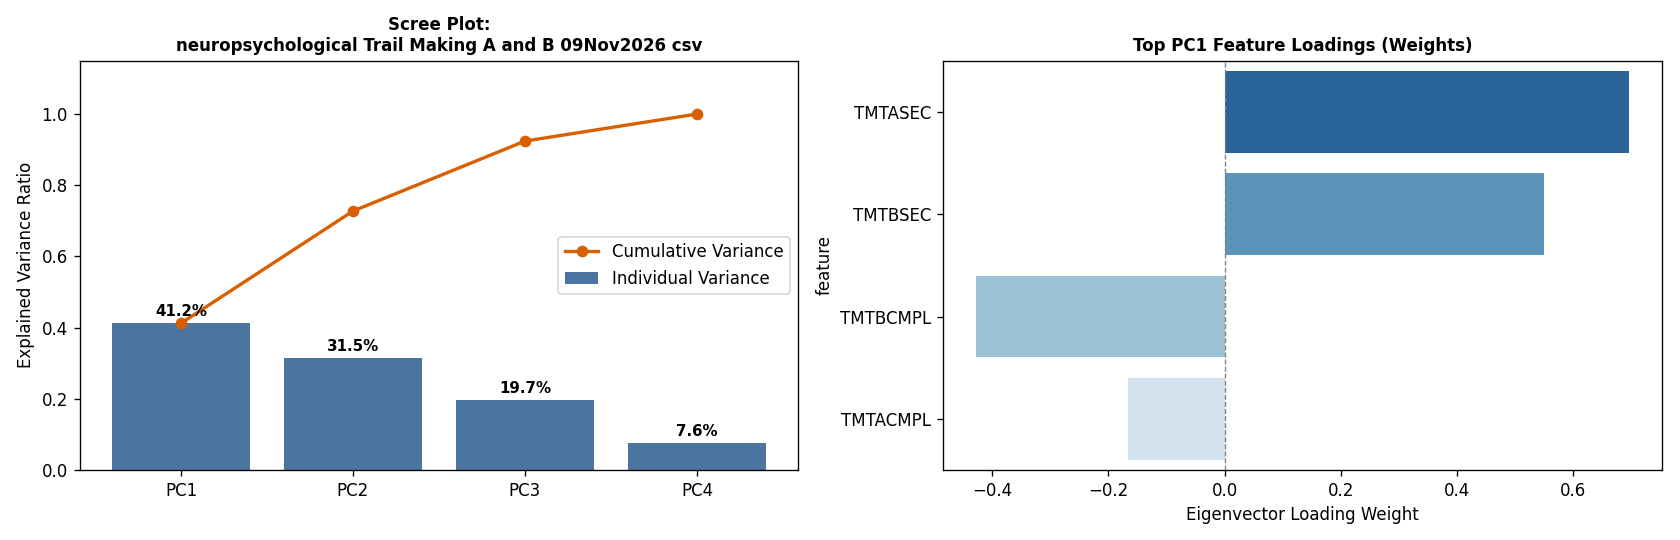

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


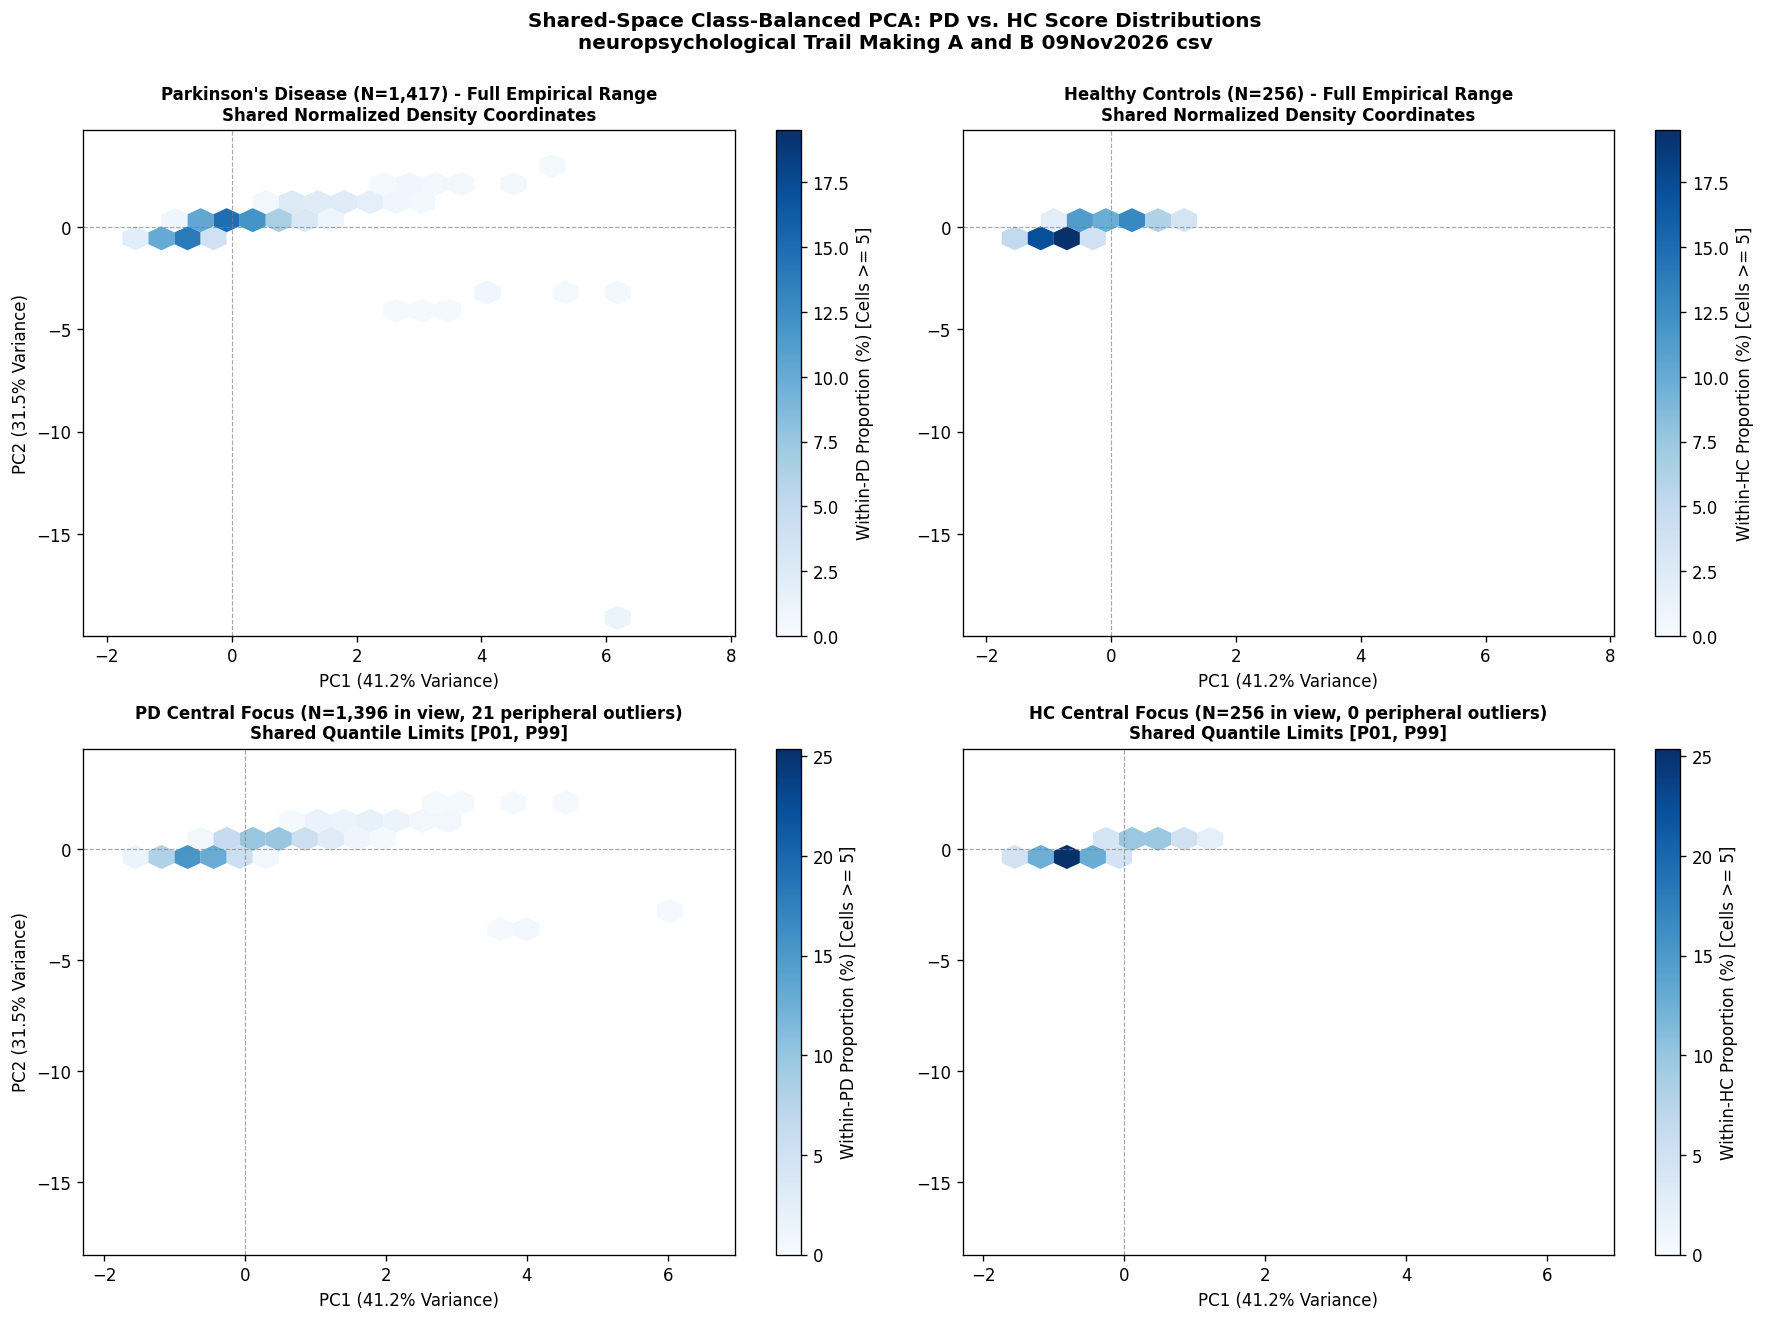

In [22]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/neuropsychological_Trail_Making_A_and_B_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/neuropsychological_Trail_Making_A_and_B_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 10 scoped analyzable unit(s) belonging to `Neuropsychological & Cognitive Function`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.